# TALUS — Phase II: Data Preprocessing & Exploratory Data Analysis (EDA)
**Physics-Informed AI for Open-Pit Mine Slope Risk Intelligence**

This notebook covers **three data sources**:

| Part | Data | Type |
|---|---|---|
| **A** | Slope-monitoring telemetry (1,245 raw field records) | Numerical / tabular |
| **B** | Rock & soil laboratory properties (488 raw samples, 8 materials) | Numerical / tabular |
| **C** | Rock & soil texture images (320 images, 8 classes) | Images |

**Method:** audit the raw data → clean it (with a reproducible pipeline in `scripts/preprocessing.py`) → verify the cleaning → explore.

> **Honest data note:** all data is **synthetic / demonstration data**. The slope table is the project's synthetic master with realistic
> data-quality faults injected (so preprocessing has real work to do, and the result can be *validated* because the true values are known).
> The images are **procedurally generated textures**, not photographs. Conclusions describe this demo data, not a real mine.

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT); sys.path.insert(0, os.path.join(ROOT, "scripts"))
import preprocessing as pp
from backend.ml_engine import PreprocessingPipeline

RAW, PROC = os.path.join(ROOT, "data", "raw"), os.path.join(ROOT, "data", "processed")
FIG = os.path.join(ROOT, "results", "eda"); os.makedirs(FIG, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.dpi"] = 100
RISK = ["Low", "Moderate", "High", "Critical"]
RCOL = {"Low": "#2ecc71", "Moderate": "#f1c40f", "High": "#e67e22", "Critical": "#e74c3c"}

def save(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG, name + ".png"), dpi=130, bbox_inches="tight"); plt.show()

print("Setup complete. Figures are also saved to results/eda/")

Setup complete. Figures are also saved to results/eda/


---
# PART A — Slope monitoring data
## A1. Load the raw field export and audit it

In [2]:
raw = pd.read_csv(os.path.join(RAW, "slope_monitoring_raw_field.csv"), dtype={"recent_blasting": str})
print("Shape:", raw.shape)
display(raw.head(8))
audit = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(),
                      "missing_%": (raw.isna().mean() * 100).round(1), "unique_values": raw.nunique()})
display(audit)

Shape: (1245, 20)


,record_id,sector_id,timestamp,slope_height_m,slope_angle_deg,cohesion_kpa,friction_angle_deg,unit_weight_kn_m3,rainfall_mm,groundwater_level,pore_pressure_kpa,deformation_rate_mm_day,displacement_mm,recent_blasting,blast_intensity,equipment_load,factor_of_safety,risk_class,risk_label,dataset_type
0,R0523,S5,2026-05-09 22:00:00,61.5,43.3,57.6,34.3,24.5,10.0,8.7,96.4,2.16,4.4,0,0.0,63.4,0.713,1,Moderate,DEMO/SYNTHETIC
1,R0857,S6,2026-07-30 19:00:00,88.8,63.2,54.1,31.3,25.4,13.3,7.5,88.3,14.34,186.4,0,0.0,62.8,0.308,3,Critical,DEMO/SYNTHETIC
2,R1079,S3,2026-07-19 07:00:00,66.4,39.4,86.9,23.6,23.9,24.6,8.9,109.1,2.15,17.5,0,0.0,16.5,0.582,2,High,DEMO/SYNTHETIC
3,R0229,S10,2026-05-03 08:00:00,124.4,51.7,69.1,NaN,27.4,4.0,19.1,187.2,3.44,NaN,0,0.0,40.5,0.300,3,Critical,DEMO/SYNTHETIC
4,R0840,S4,2026-05-23 02:00:00,150.5,60.8,71.5,20.5,21.2,4.1,11.3,114.5,6.21,46.0,0,0.0,25.8,0.230,3,Critical,DEMO/SYNTHETIC
5,R0519,S9,2026-05-02 12:00:00,90.9,28.7,42.2,30.8,26.8,23.3,4.2,59.9,1.63,0.5,0,0.0,7.4,NaN,0,Low,DEMO/SYNTHETIC
6,R0586,S5,2026-05-20 23:00:00,55.7,40.3,27.6,37.7,27.2,15.4,22.1,229.4,68.76,53.3,0,0.0,56.7,0.718,2,High,DEMO/SYNTHETIC
7,R0173,S5,2026-05-03 16:00:00,120.6,54.2,58.7,40.7,23.5,9.6,5.7,67.6,4.60,22.9,0,0.0,7.1,0.621,1,Moderate,DEMO/SYNTHETIC


,dtype,missing,missing_%,unique_values
record_id,str,0,0.0,1200
sector_id,str,0,0.0,30
timestamp,str,0,0.0,1037
slope_height_m,float64,36,2.9,772
slope_angle_deg,float64,37,3.0,352
cohesion_kpa,float64,37,3.0,622
friction_angle_deg,float64,37,3.0,241
unit_weight_kn_m3,float64,38,3.1,91
rainfall_mm,float64,36,2.9,474
groundwater_level,float64,38,3.1,281


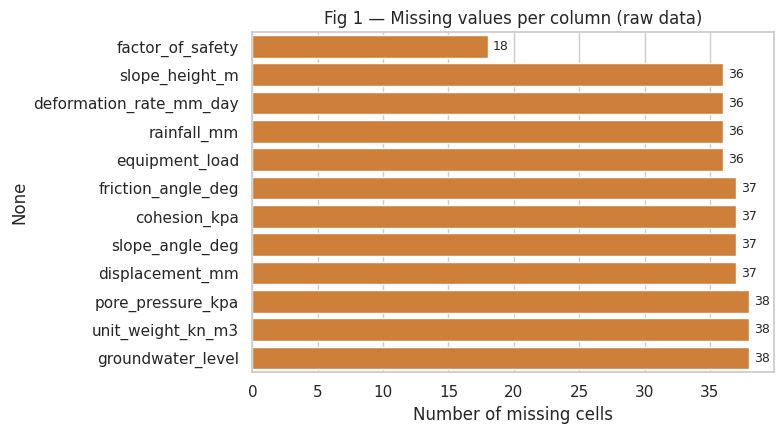

In [3]:
miss = raw.isna().sum(); miss = miss[miss > 0].sort_values()
plt.figure(figsize=(8, 4.5))
ax = sns.barplot(x=miss.values, y=miss.index, color="#e67e22")
for i, v in enumerate(miss.values): ax.text(v + 0.4, i, str(v), va="center", fontsize=9)
plt.title("Fig 1 — Missing values per column (raw data)"); plt.xlabel("Number of missing cells")
save("fig01_missing_values_raw")

**Interpretation.** Every sensor column has roughly 3 % missing readings (36–38 of 1,245 rows) and `factor_of_safety` 1.4 %. The gaps are spread
evenly (random dropouts), so they look like *missing completely at random* — **imputation is appropriate; deleting rows would waste ~30 % of the data.**

## A2. Detect the other data-quality problems

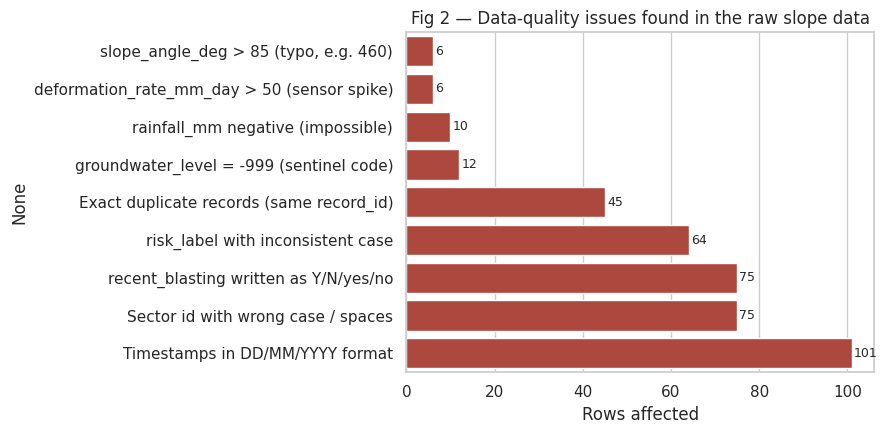

In [4]:
issues = {
    "Exact duplicate records (same record_id)": int(raw.duplicated("record_id").sum()),
    "Sector id with wrong case / spaces": int((raw.sector_id.astype(str) != raw.sector_id.astype(str).str.strip().str.upper()).sum()),
    "Timestamps in DD/MM/YYYY format": int(raw.timestamp.astype(str).str.contains("/").sum()),
    "recent_blasting written as Y/N/yes/no": int((~raw.recent_blasting.astype(str).isin(["0", "1"])).sum()),
    "risk_label with inconsistent case": int((raw.risk_label != raw.risk_label.str.capitalize()).sum()),
    "groundwater_level = -999 (sentinel code)": int((raw.groundwater_level == -999).sum()),
    "rainfall_mm negative (impossible)": int((raw.rainfall_mm < 0).sum()),
    "slope_angle_deg > 85 (typo, e.g. 460)": int((raw.slope_angle_deg > 85).sum()),
    "deformation_rate_mm_day > 50 (sensor spike)": int((raw.deformation_rate_mm_day > 50).sum()),
}
iss = pd.Series(issues).sort_values()
plt.figure(figsize=(9, 4.5)); ax = sns.barplot(x=iss.values, y=iss.index, color="#c0392b")
for i, v in enumerate(iss.values): ax.text(v + 0.5, i, str(v), va="center", fontsize=9)
plt.title("Fig 2 — Data-quality issues found in the raw slope data"); plt.xlabel("Rows affected")
save("fig02_quality_issues")

**Interpretation.** Besides gaps, the raw file has *format* problems (mixed dates, Y/N flags, upper/lower-case labels), *coded* values (-999),
*physically impossible* values (negative rain, slope angle of several hundred degrees) and *duplicated transmissions*.
Each needs a specific rule — a single "drop NaN" would leave most of them untouched.

## A3. Clean the data — `preprocessing.preprocess_slope()`
Steps applied, in order: (1) text standardisation → (2) timestamp unification → (3) Y/N → 0/1 →
(4) numeric coercion → (5) remove duplicate `record_id` → (6) domain-rule validation (impossible / sentinel → NaN) →
(7) label consistency (`risk_label` re-derived from numeric `risk_class`) → (8) imputation → (9) statistical-outlier **flagging**.

**Imputation strategy** (chosen from the EDA, not by default):
* pore pressure ← regression on groundwater level + rainfall (they are physically linked: hydrostatic head + infiltration)
* deformation rate ← displacement ÷ median ratio (displacement is accumulated deformation)
* missing Factor of Safety ← **recomputed with the project's own Limit-Equilibrium physics engine**
* everything else ← median (EDA below shows no sector-level structure that a group median could exploit)

In [5]:
clean, rep, audit_log = pp.preprocess_slope(raw)
print(f"Rows: {rep['rows_raw']} -> {rep['rows_clean']}   |   duplicates removed: {rep['duplicates_removed']}")
print(f"Missing cells: {rep['missing_before_cleaning']} originally + {rep['missing_to_impute']-rep['missing_before_cleaning']} created by invalid-value removal"
      f"  ->  {rep['missing_after_cleaning']} after imputation")
print("\nInvalid values nulled (by column):", rep["invalid_values_by_column"])
print("Imputation methods:"); [print("  -", k, ":", v) for k, v in rep["imputation"].items()]
print("\nPore-pressure model fitted on complete rows:", rep["pore_pressure_model"])
print("Statistical outliers flagged but KEPT (3xIQR):", rep["iqr_outliers_flagged_retained"])
print("\nFirst rows of the audit log (every changed cell is recorded):"); display(audit_log.head(6))

Rows: 1245 -> 1200   |   duplicates removed: 45
Missing cells: 413 originally + 34 created by invalid-value removal  ->  0 after imputation

Invalid values nulled (by column): {'slope_angle_deg': 6, 'rainfall_mm': 10, 'groundwater_level': 12, 'deformation_rate_mm_day': 6}
Imputation methods:
  - groundwater_level : median (48)
  - rainfall_mm : median (45)
  - pore_pressure_kpa : regression on groundwater+rainfall (36)
  - deformation_rate_mm_day : displacement / median ratio 9.1 d (41)
  - slope_height_m : median (36)
  - slope_angle_deg : median (42)
  - cohesion_kpa : median (36)
  - friction_angle_deg : median (36)
  - unit_weight_kn_m3 : median (36)
  - equipment_load : median (36)
  - displacement_mm : median (1)
  - factor_of_safety : recomputed by Limit-Equilibrium physics (18)

Pore-pressure model fitted on complete rows: {'intercept': 3.547, 'per_m_groundwater': 9.634, 'per_mm_rain': 0.772}
Statistical outliers flagged but KEPT (3xIQR): {'rainfall_mm': 10, 'deformation_rate_m

,record_id,column,issue,old_value,new_value
0,R0364,slope_angle_deg,"outside physical range [5, 85]",506.0,None
1,R0518,slope_angle_deg,"outside physical range [5, 85]",434.0,None
2,R0627,slope_angle_deg,"outside physical range [5, 85]",377.0,None
3,R0450,slope_angle_deg,"outside physical range [5, 85]",446.0,None
4,R0826,slope_angle_deg,"outside physical range [5, 85]",600.0,None
5,R0912,slope_angle_deg,"outside physical range [5, 85]",459.0,None


**Why the outliers are kept.** After the impossible values are removed, the remaining extreme deformation / displacement readings are *physically meaningful* —
they are precisely the events a slope-risk model must recognise. Deleting them would teach the model that slopes are safer than they are, so they are only **flagged**.

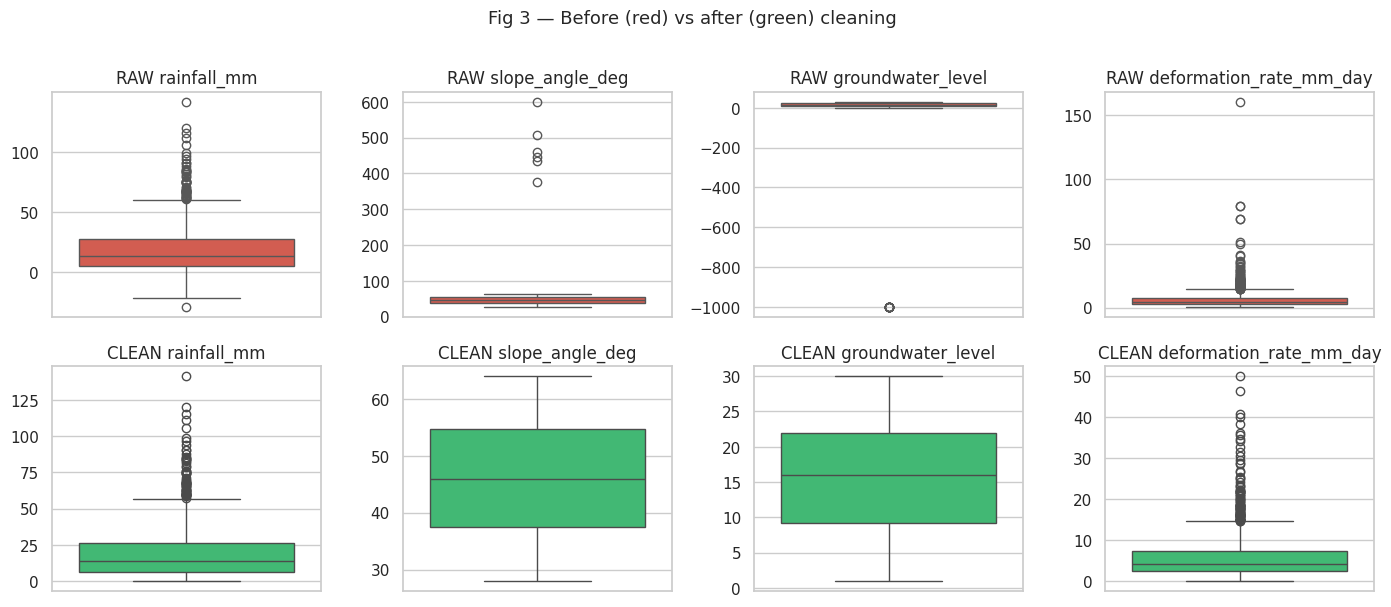

In [6]:
cols = ["rainfall_mm", "slope_angle_deg", "groundwater_level", "deformation_rate_mm_day"]
raw_num = raw.drop_duplicates("record_id")
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for j, c in enumerate(cols):
    sns.boxplot(y=pd.to_numeric(raw_num[c], errors="coerce"), ax=axes[0, j], color="#e74c3c"); axes[0, j].set_title(f"RAW {c}")
    sns.boxplot(y=clean[c], ax=axes[1, j], color="#2ecc71"); axes[1, j].set_title(f"CLEAN {c}")
    axes[0, j].set_ylabel(""); axes[1, j].set_ylabel("")
plt.suptitle("Fig 3 — Before (red) vs after (green) cleaning", y=1.01, fontsize=13)
save("fig03_before_after_boxplots")

**Interpretation.** In the raw data the -999 code, negative rainfall, slope angles of several hundred degrees and >50 mm/day spikes stretch the axes so the real
distribution is squashed. After cleaning, all four variables sit inside their physical ranges.

## A4. Validate the cleaning against the known truth
Because the faults were injected into a known master file, we can measure how well the pipeline restored the original values — something impossible with real data.

,column,cells_restored_exactly_%,mean_abs_error
0,sector_id,100.0,NaN
1,timestamp,100.0,NaN
2,slope_height_m,97.0,0.964
3,slope_angle_deg,96.6,0.270
4,cohesion_kpa,97.0,0.763
5,friction_angle_deg,97.0,0.177
6,unit_weight_kn_m3,97.0,0.061
7,rainfall_mm,96.2,0.422
8,groundwater_level,96.0,0.306
9,pore_pressure_kpa,97.1,0.154


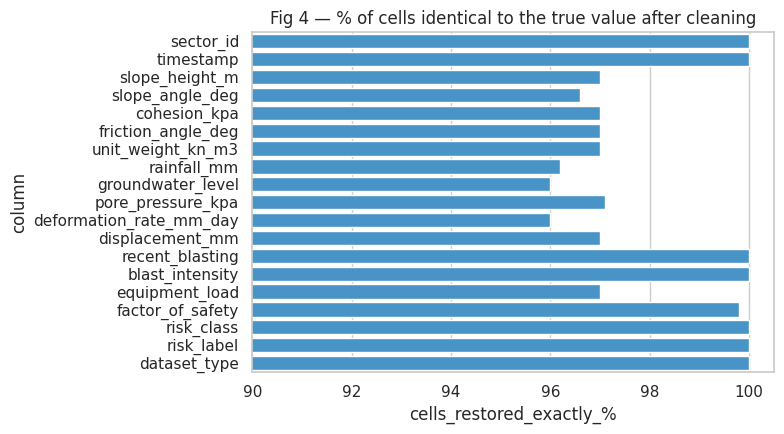

Overall: 98.1% of cells restored exactly; the remainder are imputed estimates.


In [7]:
master = pd.read_csv(os.path.join(RAW, "slope_monitoring_synthetic.csv"))
master.insert(0, "record_id", [f"R{i+1:04d}" for i in range(len(master))])
m, c = master.set_index("record_id"), clean.set_index("record_id").loc[master.record_id]
rows = []
for col in m.columns:
    if pd.api.types.is_numeric_dtype(m[col]):
        exact = np.isclose(m[col], c[col], atol=1e-2).mean(); mae = np.abs(m[col] - c[col]).mean()
    else:
        exact = (m[col].astype(str) == c[col].astype(str)).mean(); mae = np.nan
    rows.append((col, round(exact * 100, 1), None if np.isnan(mae) else round(mae, 3)))
val = pd.DataFrame(rows, columns=["column", "cells_restored_exactly_%", "mean_abs_error"])
display(val)
num = val.dropna()
plt.figure(figsize=(8, 4.5)); sns.barplot(data=val, y="column", x="cells_restored_exactly_%", color="#3498db")
plt.xlim(90, 100.5); plt.title("Fig 4 — % of cells identical to the true value after cleaning")
save("fig04_cleaning_validation")
print(f"Overall: {(np.mean([r[1] for r in rows])):.1f}% of cells restored exactly; the remainder are imputed estimates.")

**Interpretation.** Non-imputed columns (`sector_id`, `timestamp`, labels, blasting flag) are restored **100 %**. Imputed columns are ≈96–97 % identical, and the
average error on the imputed cells is small compared with each variable's range. `factor_of_safety` is recovered **exactly** because it is recomputed from physics —
a concrete benefit of the physics-informed design.
**Limitation:** ~6 of the 12 injected deformation spikes stayed under the 50 mm/day limit and cannot be told apart from genuine high readings; they remain in the data (flagged only).
A ratio-based detector was tested and *rejected* because it flagged legitimate rows.

## A5. Feature scaling & train/test split (leakage-safe)
The model uses `PreprocessingPipeline` (median-impute + z-score). It is **fitted on the training split only** and then applied to the test split, so test-set
statistics never leak into training.

Train (960, 14)  Test (240, 14)
Scaled TRAIN  mean≈0, std≈1 : 0.0 0.999
Scaled TEST   mean/std (not forced to 0/1 - correct, no leakage): 0.001 1.018
Train class share: {'Critical': 0.464, 'High': 0.333, 'Moderate': 0.176, 'Low': 0.027}
Test  class share: {'Critical': 0.454, 'High': 0.354, 'Moderate': 0.175, 'Low': 0.017}


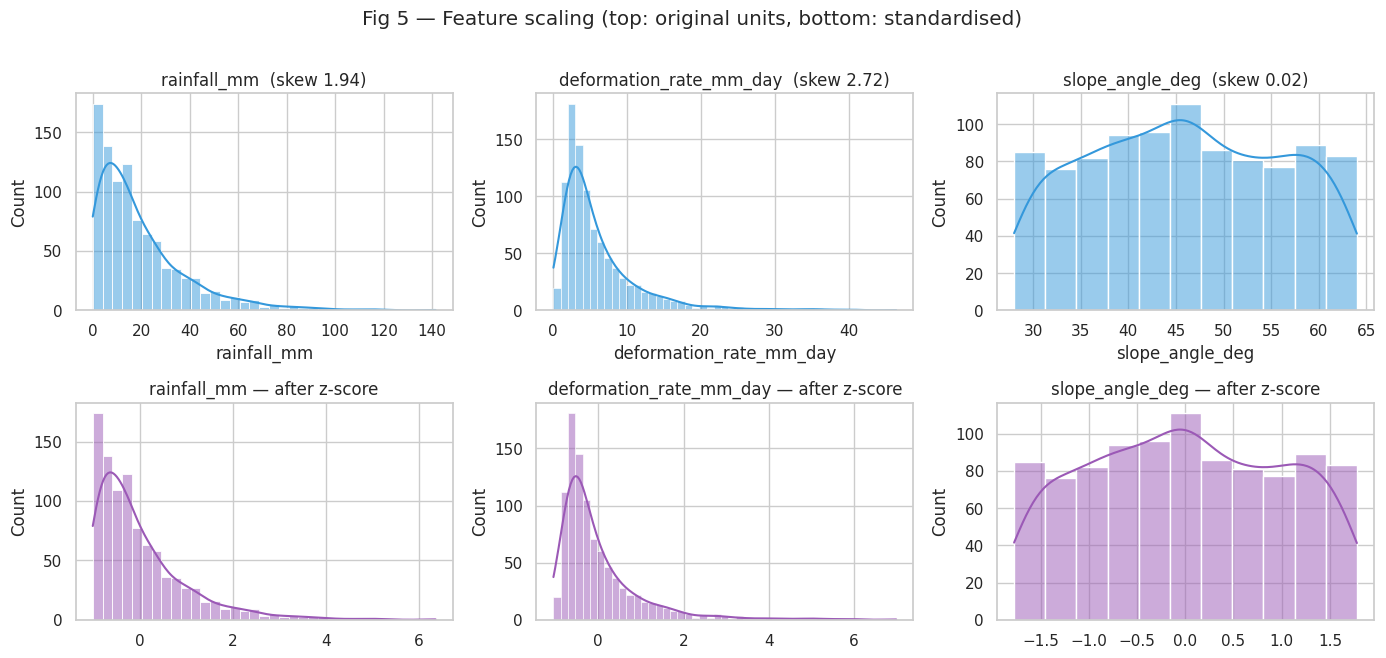

In [8]:
FEATURES = json.load(open(os.path.join(ROOT, "models", "model_metadata.json")))["feature_names"]
shuf = clean.sample(frac=1.0, random_state=42).reset_index(drop=True)
cut = int(0.8 * len(shuf)); train, test = shuf.iloc[:cut], shuf.iloc[cut:]
pipe = PreprocessingPipeline(FEATURES).fit(train)
Xtr, Xte = pipe.transform(train), pipe.transform(test)
print(f"Train {Xtr.shape}  Test {Xte.shape}")
print("Scaled TRAIN  mean≈0, std≈1 :", np.round(Xtr.mean(), 3), np.round(Xtr.std(), 3))
print("Scaled TEST   mean/std (not forced to 0/1 - correct, no leakage):", np.round(Xte.mean(), 3), np.round(Xte.std(), 3))
print("Train class share:", train.risk_label.value_counts(normalize=True).round(3).to_dict())
print("Test  class share:", test.risk_label.value_counts(normalize=True).round(3).to_dict())

fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for j, c in enumerate(["rainfall_mm", "deformation_rate_mm_day", "slope_angle_deg"]):
    sns.histplot(train[c], kde=True, ax=axes[0, j], color="#3498db"); axes[0, j].set_title(f"{c}  (skew {train[c].skew():.2f})")
    sns.histplot(Xtr[:, FEATURES.index(c)], kde=True, ax=axes[1, j], color="#9b59b6"); axes[1, j].set_title(f"{c} — after z-score")
plt.suptitle("Fig 5 — Feature scaling (top: original units, bottom: standardised)", y=1.01)
save("fig05_scaling")

**Interpretation.** Standardisation puts all 14 features on a common scale (essential for logistic regression / SVM). It does **not** remove skew:
`rainfall_mm` (skew 1.9) and `deformation_rate_mm_day` (2.9) stay right-skewed. Tree models are unaffected; for linear models a `log1p` transform of these two
features is a worthwhile future experiment. Train and test have very similar class mixes, so the split is representative.

---
## A6. Exploratory Data Analysis of the cleaned slope data

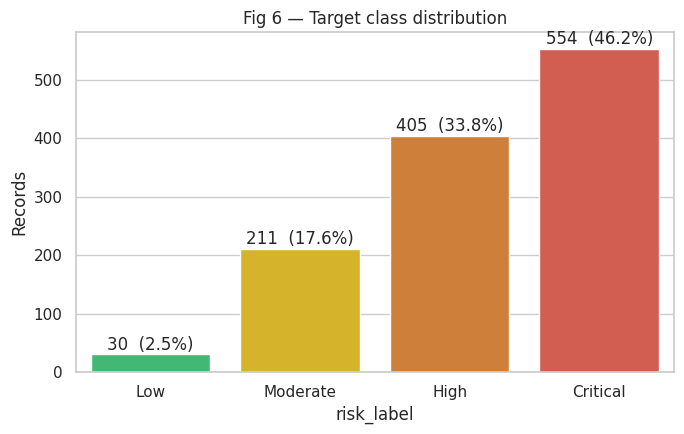

In [9]:
d = clean.copy()
d["risk_label"] = pd.Categorical(d["risk_label"], RISK, ordered=True)
vc = d.risk_label.value_counts().reindex(RISK)
plt.figure(figsize=(7, 4.5)); ax = sns.barplot(x=vc.index, y=vc.values, palette=[RCOL[k] for k in RISK])
for i, v in enumerate(vc.values): ax.text(i, v + 8, f"{v}  ({v/len(d):.1%})", ha="center")
plt.title("Fig 6 — Target class distribution"); plt.ylabel("Records")
save("fig06_class_distribution")

**Interpretation — important.** The classes are **not balanced**: *Critical* is 46 % and *High* 34 %, while *Low* is only **2.5 % (30 records)**. Any model will
see very few Low examples, so **accuracy alone is misleading** — the project correctly selects models by F1-score, and per-class recall should be reported.
Also, 93 % of records have Factor of Safety < 1, which is far more unstable than a real operating mine; this reflects how the synthetic generator was parameterised.

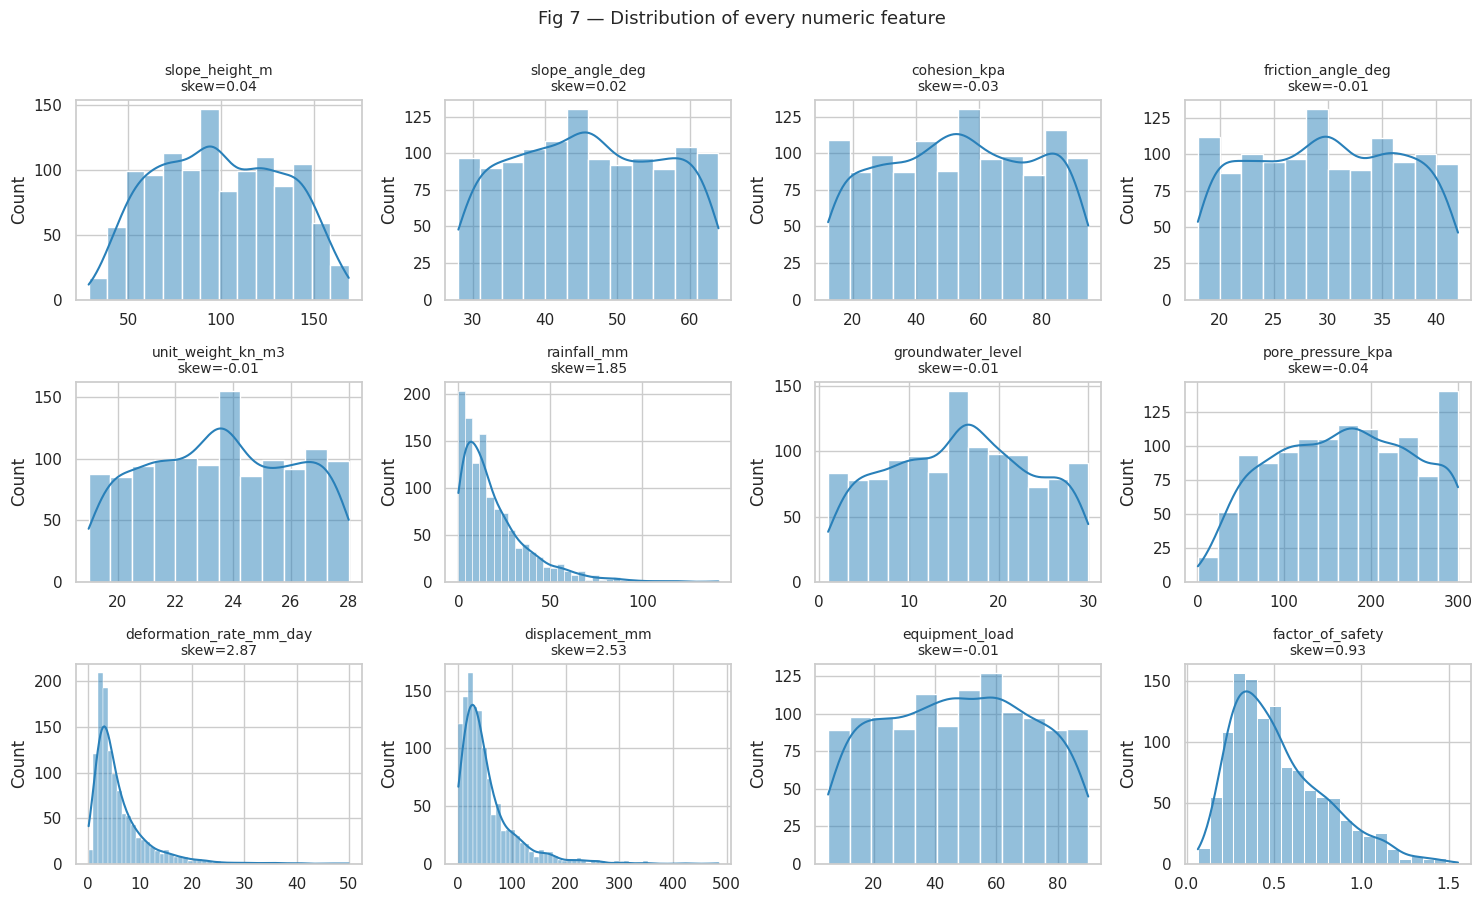

In [10]:
feat_plot = ["slope_height_m","slope_angle_deg","cohesion_kpa","friction_angle_deg","unit_weight_kn_m3","rainfall_mm",
             "groundwater_level","pore_pressure_kpa","deformation_rate_mm_day","displacement_mm","equipment_load","factor_of_safety"]
fig, axes = plt.subplots(3, 4, figsize=(15, 9))
for ax, c in zip(axes.ravel(), feat_plot):
    sns.histplot(d[c], kde=True, ax=ax, color="#2980b9"); ax.set_title(f"{c}\nskew={d[c].skew():.2f}", fontsize=10); ax.set_xlabel("")
plt.suptitle("Fig 7 — Distribution of every numeric feature", y=1.0, fontsize=13)
save("fig07_feature_distributions")

**Interpretation.** Height, angle, cohesion, friction, unit weight, groundwater and equipment load are roughly **uniform** (typical of synthetic generation), whereas
rainfall, deformation rate and displacement are **right-skewed** (many small values, few extreme events — realistic). Factor of Safety is bounded and compressed
below 1.5.

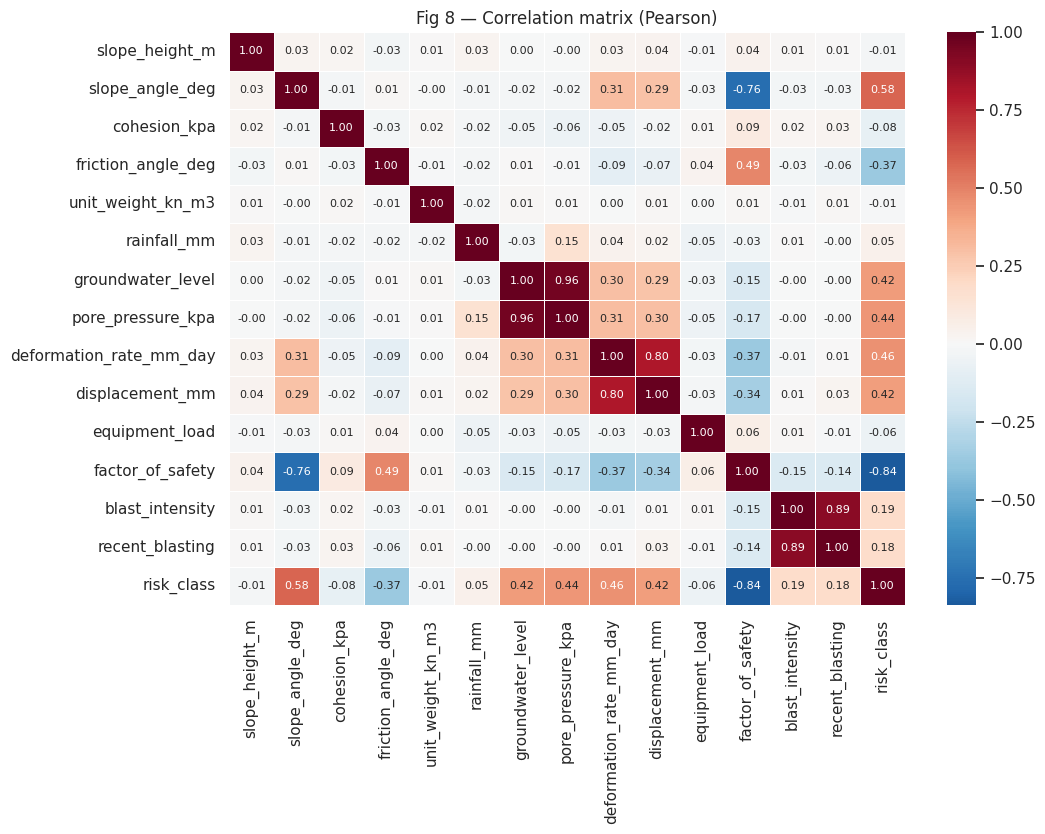

risk_class                -0.84
slope_angle_deg           -0.76
deformation_rate_mm_day   -0.37
displacement_mm           -0.34
pore_pressure_kpa         -0.17
groundwater_level         -0.15
blast_intensity           -0.15
recent_blasting           -0.14
rainfall_mm               -0.03
unit_weight_kn_m3          0.01
slope_height_m             0.04
equipment_load             0.06
cohesion_kpa               0.09
friction_angle_deg         0.49


In [11]:
corr = d[feat_plot + ["blast_intensity", "recent_blasting", "risk_class"]].corr()
plt.figure(figsize=(11, 8.5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 8}, linewidths=.4)
plt.title("Fig 8 — Correlation matrix (Pearson)"); save("fig08_correlation")
print(corr["factor_of_safety"].drop("factor_of_safety").sort_values().round(2).to_string())

**Interpretation.**
* **Slope angle is the dominant driver of Factor of Safety (r = −0.76)**; friction angle is next (+0.49). Deformation rate (−0.37) and displacement (−0.34) also fall as FoS falls.
* `risk_class` correlates most strongly with FoS (−0.84), then slope angle (+0.58), deformation rate (+0.46), pore pressure (+0.44) and groundwater level (+0.42).
* **Pore pressure and groundwater level are almost the same signal (r = 0.96)** — strong multicollinearity; linear-model coefficients for these two should not be interpreted separately.
* **Rainfall shows essentially no direct correlation with risk (r ≈ 0.05)** in this dataset because rain enters only through a small term in pore pressure. Do not claim rainfall is a major driver from this data.

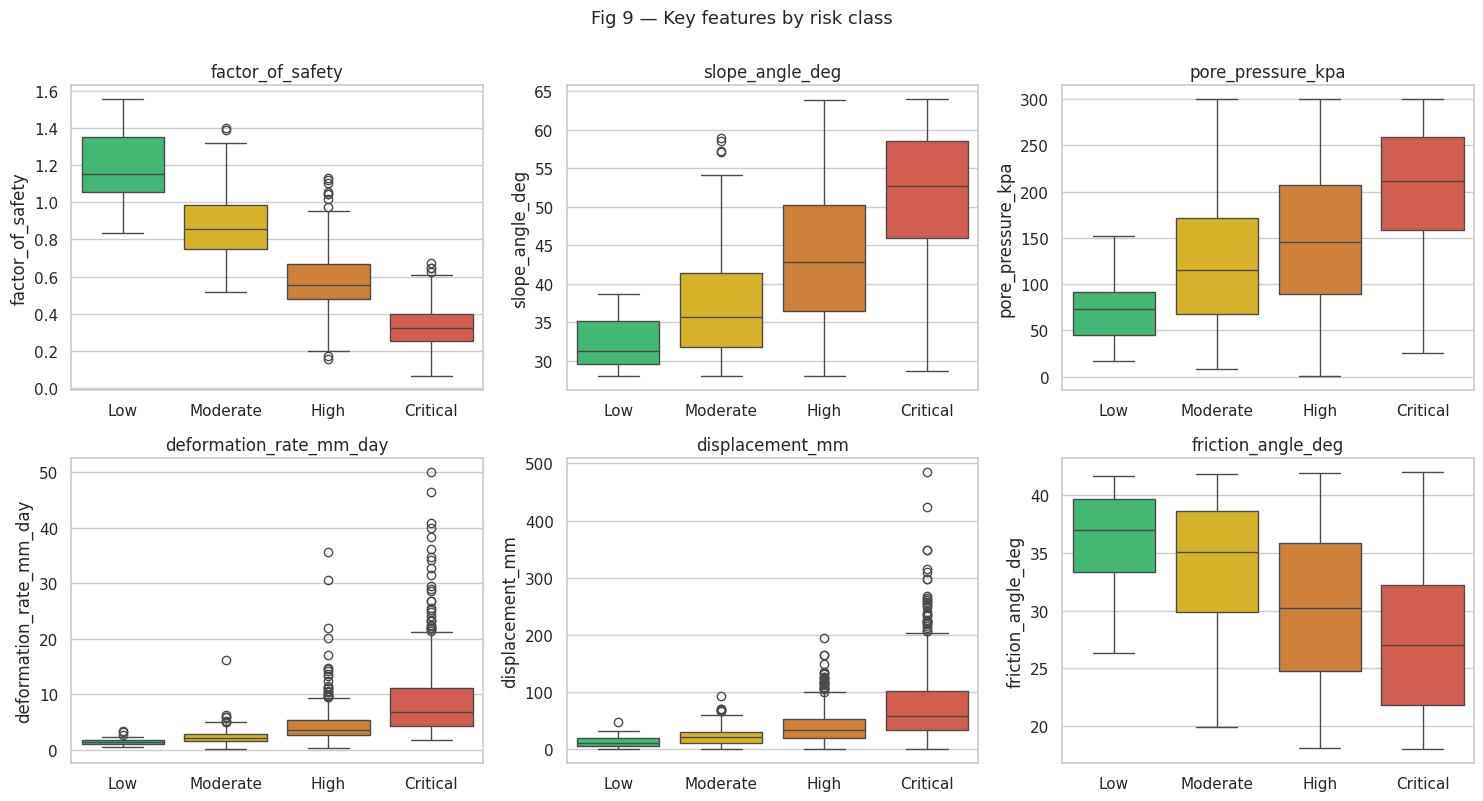

            factor_of_safety  slope_angle_deg  pore_pressure_kpa  \
risk_label                                                         
Low                     1.15            31.20              72.80   
Moderate                0.86            35.70             115.40   
High                    0.55            42.80             145.90   
Critical                0.32            52.75             211.95   

            deformation_rate_mm_day  
risk_label                           
Low                            1.29  
Moderate                       2.10  
High                           3.58  
Critical                       6.82  


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), ["factor_of_safety","slope_angle_deg","pore_pressure_kpa","deformation_rate_mm_day","displacement_mm","friction_angle_deg"]):
    sns.boxplot(data=d, x="risk_label", y=c, order=RISK, palette=RCOL, ax=ax); ax.set_xlabel(""); ax.set_title(c)
plt.suptitle("Fig 9 — Key features by risk class", y=1.0, fontsize=13); save("fig09_features_by_risk")
print(d.groupby("risk_label")[["factor_of_safety","slope_angle_deg","pore_pressure_kpa","deformation_rate_mm_day"]].median().round(2))

**Interpretation.** Class separation is clear and monotonic for FoS (median 1.15 → 0.32 from Low to Critical), slope angle (31° → 53°), pore pressure (73 → 212 kPa) and deformation rate.
Friction angle is *lower* in higher-risk classes. Classes overlap most for the middle categories (Moderate/High), which is where a classifier will make most of its errors.

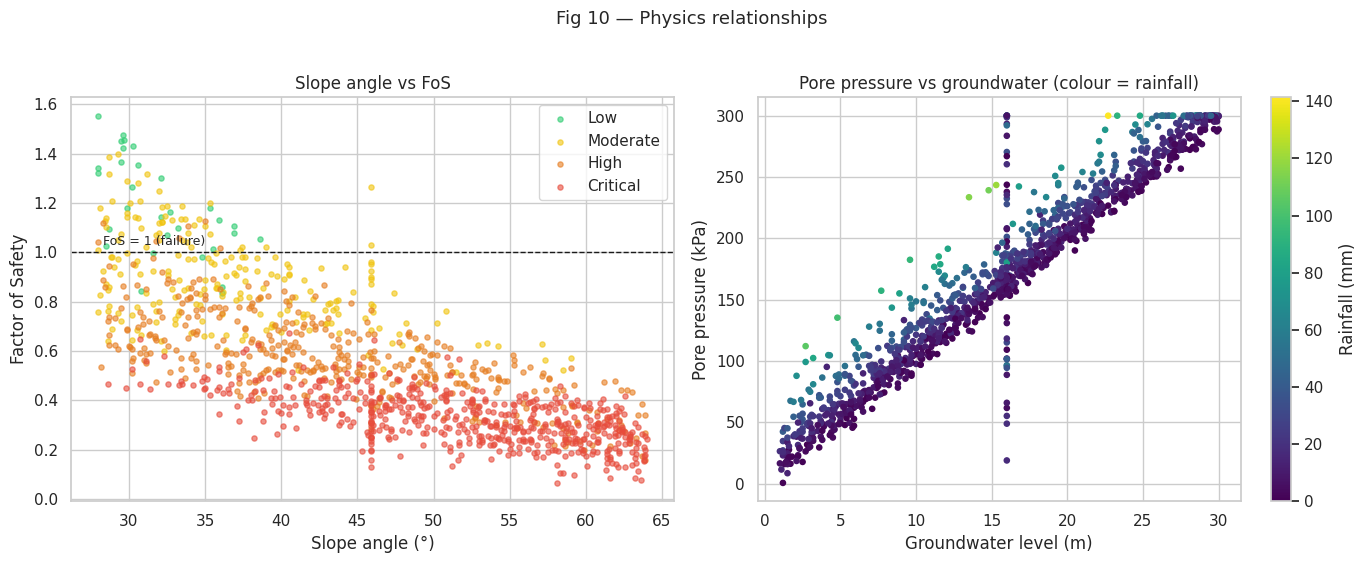

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for k in RISK:
    s = d[d.risk_label == k]; ax[0].scatter(s.slope_angle_deg, s.factor_of_safety, s=14, alpha=.6, c=RCOL[k], label=k)
ax[0].axhline(1.0, color="k", ls="--", lw=1); ax[0].text(28.3, 1.03, "FoS = 1 (failure)", fontsize=9)
ax[0].set(xlabel="Slope angle (°)", ylabel="Factor of Safety", title="Slope angle vs FoS"); ax[0].legend()
sc = ax[1].scatter(d.groundwater_level, d.pore_pressure_kpa, c=d.rainfall_mm, cmap="viridis", s=14)
plt.colorbar(sc, ax=ax[1], label="Rainfall (mm)"); ax[1].set(xlabel="Groundwater level (m)", ylabel="Pore pressure (kPa)", title="Pore pressure vs groundwater (colour = rainfall)")
plt.suptitle("Fig 10 — Physics relationships", y=1.02, fontsize=13); save("fig10_physics_relationships")

**Interpretation.** Left: FoS falls steadily as slope angle rises, and the point cloud lies almost entirely below the FoS = 1 line — consistent with the 93 % share noted earlier.
Right: pore pressure rises linearly with groundwater level (≈9.6 kPa per metre, close to the hydrostatic 9.81 kPa/m); rainfall adds a smaller upward shift (colour gradient) —
this is the physical relationship the regression-based imputation exploits.

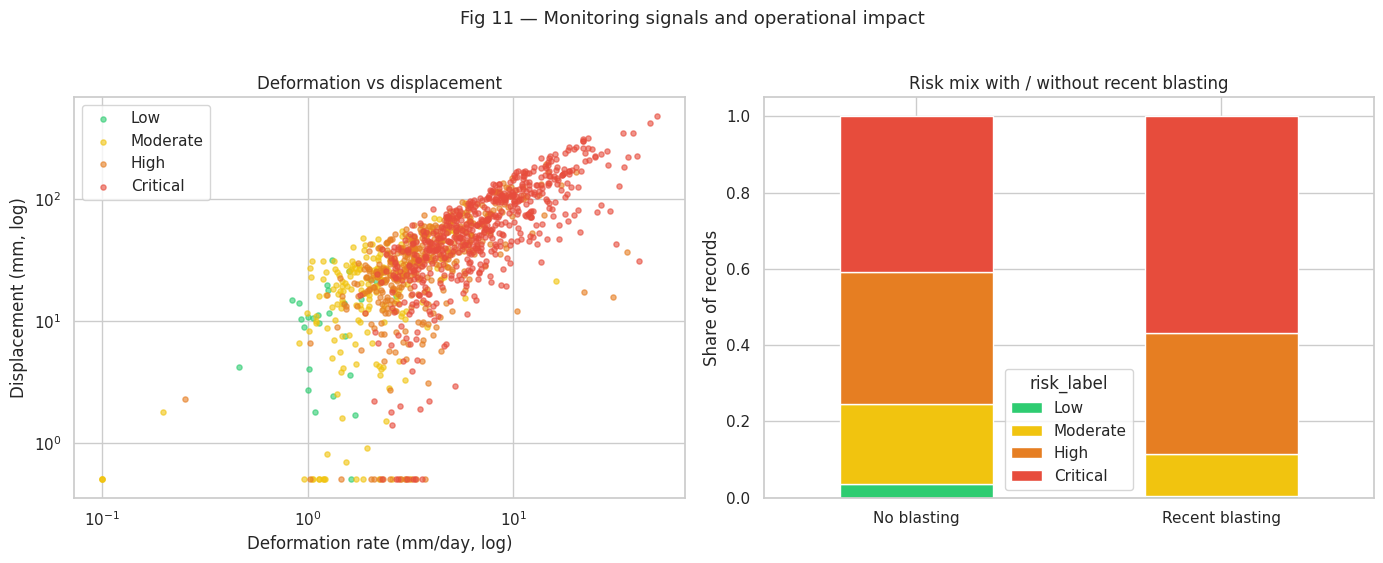

Mean risk class (0-3): no blasting = 2.13 | blasting = 2.45
Share Critical: no blasting = 0.407 | blasting = 0.568


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for k in RISK:
    s = d[d.risk_label == k]; ax[0].scatter(s.deformation_rate_mm_day, s.displacement_mm, s=14, alpha=.6, c=RCOL[k], label=k)
ax[0].set(xscale="log", yscale="log", xlabel="Deformation rate (mm/day, log)", ylabel="Displacement (mm, log)", title="Deformation vs displacement"); ax[0].legend()
ct = pd.crosstab(d.recent_blasting.map({0: "No blasting", 1: "Recent blasting"}), d.risk_label, normalize="index")[RISK]
ct.plot(kind="bar", stacked=True, color=[RCOL[k] for k in RISK], ax=ax[1], rot=0); ax[1].set(ylabel="Share of records", title="Risk mix with / without recent blasting", xlabel="")
plt.suptitle("Fig 11 — Monitoring signals and operational impact", y=1.02, fontsize=13); save("fig11_deformation_blasting")
print("Mean risk class (0-3): no blasting =", round(d[d.recent_blasting==0].risk_class.mean(), 2), "| blasting =", round(d[d.recent_blasting==1].risk_class.mean(), 2))
print("Share Critical: no blasting =", round((d[d.recent_blasting==0].risk_label=="Critical").mean(), 3), "| blasting =", round((d[d.recent_blasting==1].risk_label=="Critical").mean(), 3))

**Interpretation.** Displacement grows with deformation rate (r ≈ 0.80) and the high-risk classes sit in the upper-right, as expected for accumulated movement.
Sectors with **recent blasting have a higher average risk class (2.45 vs 2.13)** — a moderate operational effect, consistent with the blast term in the physics model.

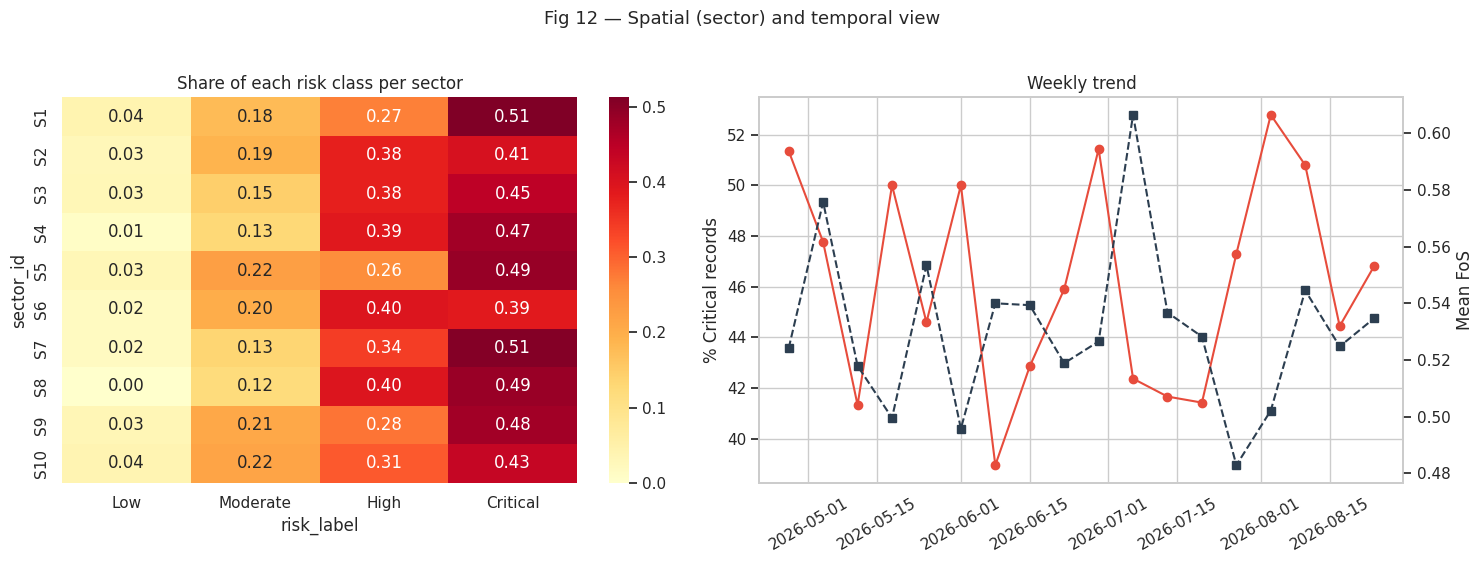

Mean risk class per sector: {'S1': 2.25, 'S10': 2.14, 'S2': 2.16, 'S3': 2.24, 'S4': 2.33, 'S5': 2.2, 'S6': 2.15, 'S7': 2.34, 'S8': 2.37, 'S9': 2.2}


In [15]:
sec = d.pivot_table(index="sector_id", columns="risk_label", values="record_id", aggfunc="count", fill_value=0)[RISK]
sec = sec.loc[sorted(sec.index, key=lambda s: int(s[1:]))]
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(sec.div(sec.sum(1), axis=0), annot=True, fmt=".2f", cmap="YlOrRd", ax=ax[0]); ax[0].set_title("Share of each risk class per sector")
dd = d.copy(); dd["week"] = pd.to_datetime(dd.timestamp).dt.to_period("W").dt.start_time
wk = dd.groupby("week").agg(fos=("factor_of_safety", "mean"), critical=("risk_label", lambda s: (s == "Critical").mean()))
ax[1].plot(wk.index, wk.critical * 100, "o-", color="#e74c3c", label="% Critical"); ax[1].set_ylabel("% Critical records")
a2 = ax[1].twinx(); a2.plot(wk.index, wk.fos, "s--", color="#2c3e50", label="mean FoS"); a2.set_ylabel("Mean FoS"); a2.grid(False)
ax[1].set_title("Weekly trend"); ax[1].tick_params(axis="x", rotation=30)
plt.suptitle("Fig 12 — Spatial (sector) and temporal view", y=1.02, fontsize=13); save("fig12_sector_time")
print("Mean risk class per sector:", d.groupby("sector_id").risk_class.mean().round(2).to_dict())

**Interpretation.** No sector stands out: mean risk class is 2.1–2.4 in **all ten sectors**, and the weekly share of Critical records bounces between about 40 % and 53 % with no consistent direction. In this synthetic dataset sector identity carries
**no information** (records were assigned to sectors at random) — which is exactly why a plain median was used for imputation, and why a sector-specific model would not help.
In a real mine, sector and time would be among the most informative variables.

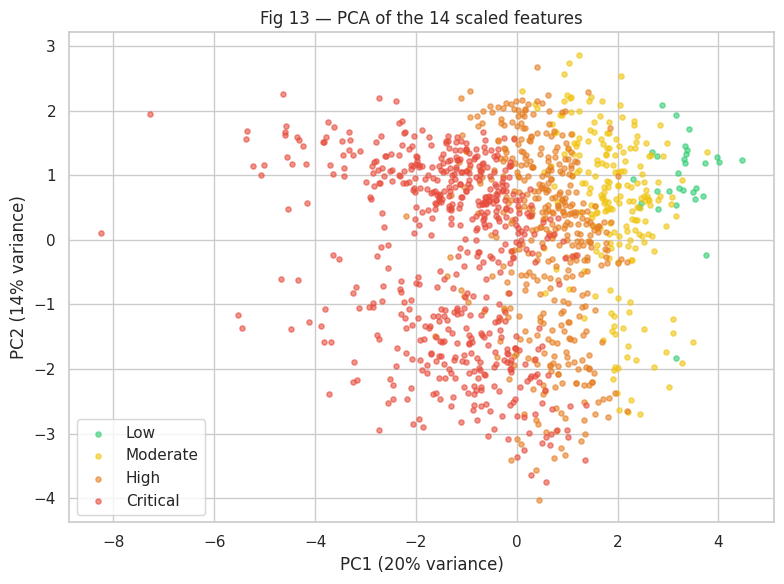

Variance explained by first 2 / 4 components: 34% / 55%


In [16]:
Z = PreprocessingPipeline(FEATURES).fit_transform(d)
U, S, Vt = np.linalg.svd(Z - Z.mean(0), full_matrices=False)
pc = U[:, :2] * S[:2]; ev = (S ** 2) / (S ** 2).sum()
plt.figure(figsize=(8, 6))
for k in RISK:
    m_ = (d.risk_label == k).values; plt.scatter(pc[m_, 0], pc[m_, 1], s=14, alpha=.6, c=RCOL[k], label=k)
plt.xlabel(f"PC1 ({ev[0]:.0%} variance)"); plt.ylabel(f"PC2 ({ev[1]:.0%} variance)"); plt.legend(); plt.title("Fig 13 — PCA of the 14 scaled features")
save("fig13_pca")
print("Variance explained by first 2 / 4 components:", f"{ev[:2].sum():.0%} / {ev[:4].sum():.0%}")

**Interpretation.** In two dimensions the risk classes already form an ordered gradient (Low → Critical) with overlap in the middle — evidence that the features carry real
signal and that a non-trivial classifier is worthwhile. Because the first two components explain under half of the variance, the problem is not reducible to two variables.

---
# PART B — Rock & soil laboratory properties (numerical)
Eight materials — 5 rocks (granite, basalt, sandstone, limestone, shale) and 3 soils (clay, sandy soil, gravel colluvium).
Values are typical / illustrative geotechnical ranges (synthetic samples, **not** measurements from a real mine).

In [17]:
rs_raw = pd.read_csv(os.path.join(RAW, "rock_soil_properties.csv"))
rs, rrep = pp.preprocess_rock_soil(rs_raw)
print("Raw:", rs_raw.shape, " Clean:", rs.shape)
print("Material spellings in raw file :", rs_raw.material.nunique(), "-> after cleaning:", rs.material.nunique())
print("Report:", json.dumps({k: v for k, v in rrep.items()}, indent=1))
display(rs_raw.isna().sum()[lambda s: s > 0].to_frame("missing_in_raw").T)

Raw: (488, 14)  Clean: (480, 14)
Material spellings in raw file : 23 -> after cleaning: 8
Report: {
 "rows_raw": 488,
 "material_names_fixed": 26,
 "duplicates_removed": 8,
 "unit_weight_gcm3_converted": 10,
 "invalid_values_by_column": {
  "friction_angle_deg": 5
 },
 "missing_to_impute": 111,
 "missing_after_cleaning": 0,
 "legit_missing_soil_rqd_gsi": 360,
 "rows_clean": 480
}


,unit_weight_kn_m3,compressive_strength_mpa,cohesion_kpa,friction_angle_deg,porosity_pct,moisture_content_pct,log10_permeability_m_s,rqd_pct,gsi
missing_in_raw,12,13,13,12,12,13,12,194,192


**Cleaning applied.** 23 spellings of 8 materials were unified; 8 duplicate samples removed; **unit weights recorded in g/cm³ (values ≈ 2–3) were converted to kN/m³ (× 9.81)**;
impossible values (e.g. a friction angle of 480°) were nulled; gaps were filled with the **median of the same material** (a granite gap is filled from granite, not from clay).
`RQD` and `GSI` are rock-mass indices that do not apply to soil, so those blanks are **legitimate and intentionally not imputed**.

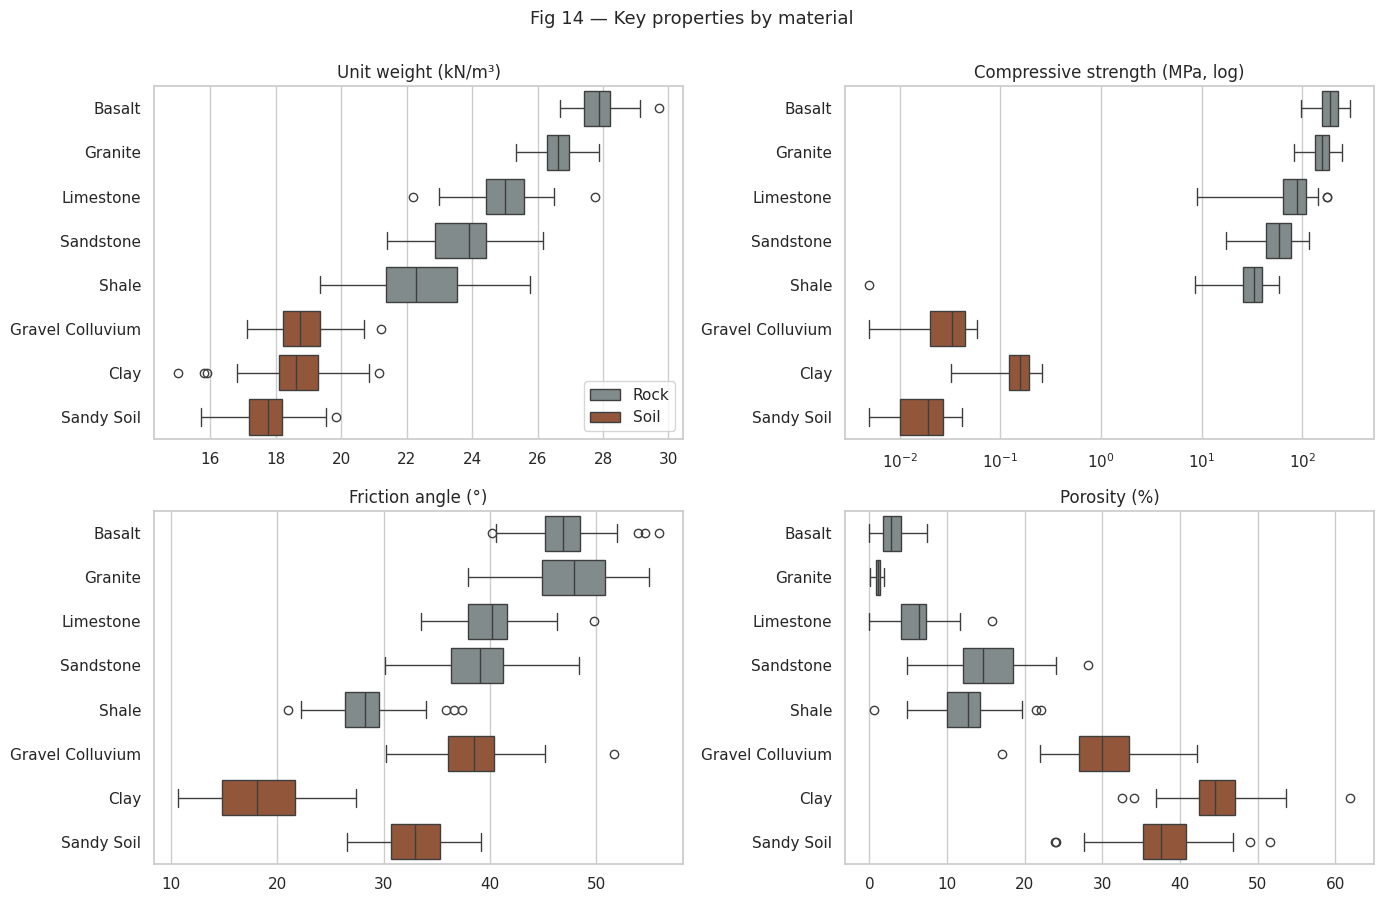

                  unit_weight_kn_m3  compressive_strength_mpa  \
material                                                        
Basalt                        27.88                    188.59   
Clay                          18.62                      0.16   
Granite                       26.64                    158.17   
Gravel Colluvium              18.73                      0.03   
Limestone                     25.02                     88.08   
Sandstone                     23.91                     57.93   
Sandy Soil                    17.76                      0.02   
Shale                         22.27                     32.76   

                  friction_angle_deg  porosity_pct  
material                                            
Basalt                         46.90          2.80  
Clay                           18.05         44.55  
Granite                        47.90          1.10  
Gravel Colluvium               38.50         30.00  
Limestone                      

In [18]:
props = [("unit_weight_kn_m3", "Unit weight (kN/m³)"), ("compressive_strength_mpa", "Compressive strength (MPa, log)"),
         ("friction_angle_deg", "Friction angle (°)"), ("porosity_pct", "Porosity (%)")]
order = rs.groupby("material").unit_weight_kn_m3.median().sort_values(ascending=False).index
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (c, t) in zip(axes.ravel(), props):
    sns.boxplot(data=rs, y="material", x=c, order=order, hue="material_type", dodge=False, palette={"Rock": "#7f8c8d", "Soil": "#a0522d"}, ax=ax)
    ax.set_title(t); ax.set_ylabel(""); ax.set_xlabel("")
    if "strength" in c: ax.set_xscale("log")
    ax.legend(title="", loc="lower right") if c == "unit_weight_kn_m3" else ax.get_legend().remove()
plt.suptitle("Fig 14 — Key properties by material", y=1.0, fontsize=13); save("fig14_rock_soil_properties")
print(rs.groupby("material")[["unit_weight_kn_m3","compressive_strength_mpa","friction_angle_deg","porosity_pct"]].median().round(2))

**Interpretation.** Materials form two clear families. **Rocks** are heavy (22–28 kN/m³), strong (tens to hundreds of MPa) and low-porosity (1–15 %); **soils** are lighter (17–19 kN/m³),
hundreds to thousands of times weaker and highly porous (30–45 %). Within rocks the ranking granite/basalt > limestone > sandstone > shale matches engineering experience — **shale is the weak, high-porosity
rock and the natural suspect for slope instability**. Clay has the lowest friction angle (~18°) among soils, sandy/gravelly soils the highest.

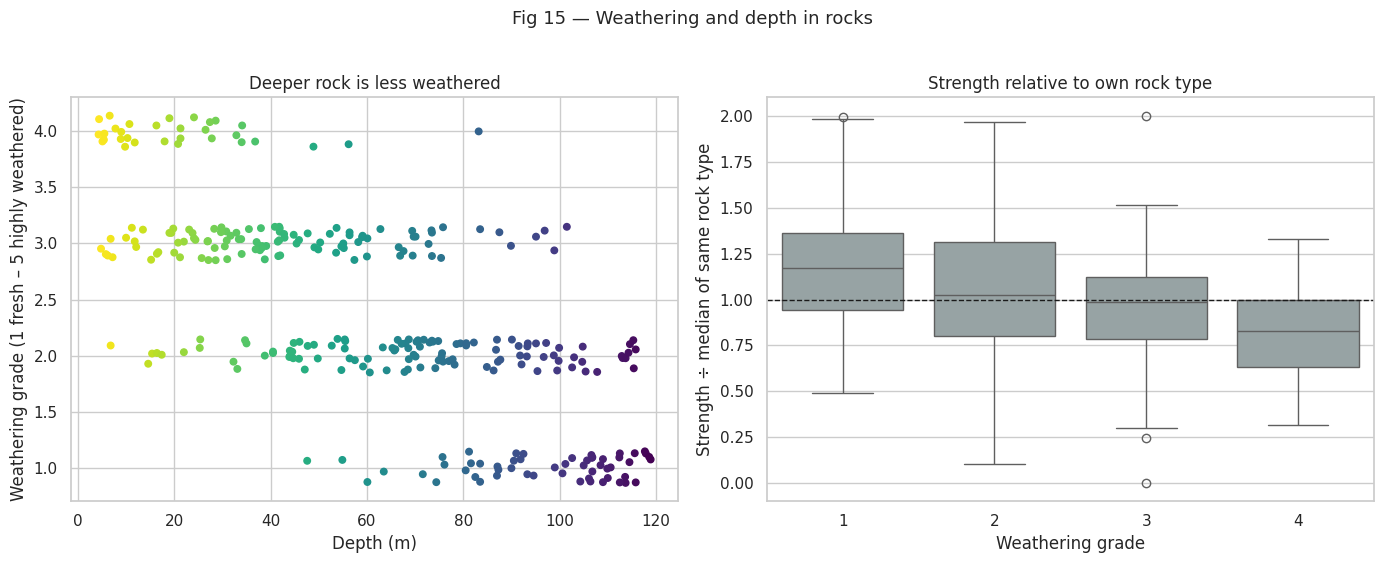

corr(depth, weathering grade)                 = -0.71
corr(weathering grade, raw strength - all rocks) = -0.11 (weak: rock TYPE dominates)
corr(weathering grade, strength / rock-type median) = -0.28
{1: 1.17, 2: 1.02, 3: 0.99, 4: 0.83}


In [19]:
rk = rs[rs.material_type == "Rock"]
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
rk = rk.assign(rel_strength=rk.compressive_strength_mpa / rk.groupby("material").compressive_strength_mpa.transform("median"))
sc = ax[0].scatter(rk.depth_m, rk.weathering_grade + np.random.default_rng(0).uniform(-.15, .15, len(rk)), c=rk.depth_m, cmap="viridis_r", s=22)
ax[0].set(xlabel="Depth (m)", ylabel="Weathering grade (1 fresh – 5 highly weathered)", title="Deeper rock is less weathered")
sns.boxplot(data=rk, x="weathering_grade", y="rel_strength", ax=ax[1], color="#95a5a6")
ax[1].set(xlabel="Weathering grade", ylabel="Strength ÷ median of same rock type", title="Strength relative to own rock type"); ax[1].axhline(1, color="k", ls="--", lw=1)
plt.suptitle("Fig 15 — Weathering and depth in rocks", y=1.02, fontsize=13); save("fig15_weathering")
print("corr(depth, weathering grade)                 =", round(rk.depth_m.corr(rk.weathering_grade), 2))
print("corr(weathering grade, raw strength - all rocks) =", round(rk.weathering_grade.corr(rk.compressive_strength_mpa), 2), "(weak: rock TYPE dominates)")
print("corr(weathering grade, strength / rock-type median) =", round(rk.weathering_grade.corr(rk.rel_strength), 2))
print(rk.groupby("weathering_grade").rel_strength.median().round(2).to_dict())

**Interpretation.** Deeper rock is less weathered (depth vs weathering grade r ≈ −0.71). Across *all* rocks the raw correlation between weathering and strength is weak (≈ −0.11) because
rock **type** dominates (granite at grade 4 is still stronger than shale at grade 1). Once each sample is compared with the median of its own rock type (right panel), strength clearly declines as weathering increases.
So near-surface, weathered material is weakest for its type — one reason weathered benches and slope faces fail first — and rock type must be part of any slope model.

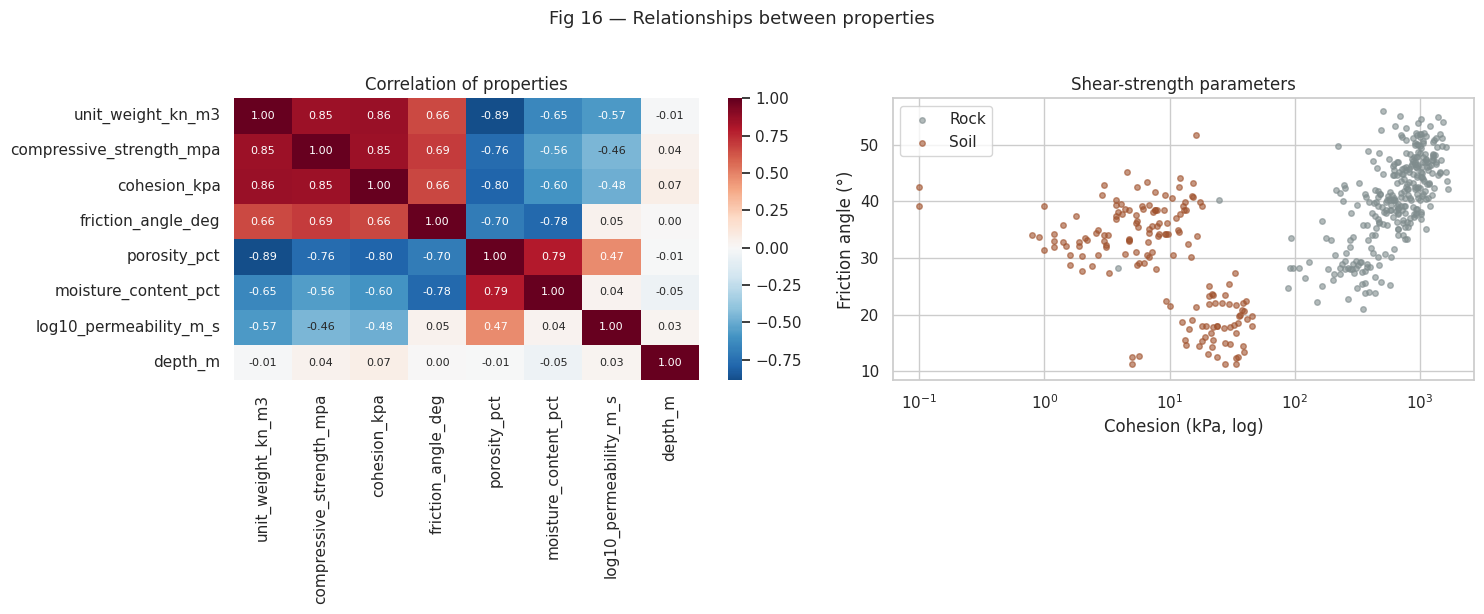

In [20]:
cc = ["unit_weight_kn_m3","compressive_strength_mpa","cohesion_kpa","friction_angle_deg","porosity_pct","moisture_content_pct","log10_permeability_m_s","depth_m"]
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(rs[cc].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 8}, ax=ax[0]); ax[0].set_title("Correlation of properties")
for t, col in [("Rock", "#7f8c8d"), ("Soil", "#a0522d")]:
    s = rs[rs.material_type == t]; ax[1].scatter(s.cohesion_kpa, s.friction_angle_deg, s=16, alpha=.6, c=col, label=t)
ax[1].set(xscale="log", xlabel="Cohesion (kPa, log)", ylabel="Friction angle (°)", title="Shear-strength parameters"); ax[1].legend()
plt.suptitle("Fig 16 — Relationships between properties", y=1.02, fontsize=13); save("fig16_property_correlations")

**Interpretation.** Strength, cohesion and unit weight are strongly positively related to each other and negatively to porosity and moisture — dense, dry, low-porosity material is strong.
The cohesion–friction plot separates **rock (high cohesion, high friction)** from **soil (low cohesion)**; these two parameters are exactly the `c'` and `φ'` inputs of the Factor-of-Safety equation.
Note that the slope dataset uses cohesion of 12–95 kPa (a weathered / jointed rock-mass or soil-like range) — the lab values here are for intact material, so they should not be plugged in directly.

---
# PART C — Rock & soil images
320 images (40 per class × 8 classes), 128 × 128 px. **Procedurally generated textures** that imitate each material's visual signature (grain speckle, bedding, laminations,
desiccation cracks, angular clasts). Each image is randomly *dry* or *wet* and has random lighting. Real photographs can be dropped into `data/raw/images/<class>/` and this same pipeline will process them.
## C1. Image preprocessing pipeline
Steps (in `preprocessing.preprocess_images`): verify each file opens → convert to RGB → resize to 128×128 → remove near-duplicates (average hash) → quality gate (reject nearly black / blown-out / flat frames)
→ extract 14 colour & texture features (brightness, contrast, saturation, hue, entropy, edge density, sharpness, four GLCM texture measures) → compute dataset channel mean/std → stratified 80/20 split.

In [21]:
imgs, irep, istats = pp.preprocess_images()
print(json.dumps(irep, indent=1)); print("Channel mean (RGB):", istats["channel_mean_rgb"], "| std:", istats["channel_std_rgb"])
display(imgs.head(4)[["image_id","material","moisture_state","brightness","contrast","entropy","edge_density","glcm_homogeneity","split"]])

{
 "files_found": 320,
 "unreadable_removed": 0,
 "duplicates_removed": 0,
 "quality_rejected": 0,
 "images_kept": 320,
 "classes": 8,
 "train": 256,
 "test": 64
}
Channel mean (RGB): [0.467, 0.3964, 0.3285] | std: [0.2312, 0.2094, 0.1896]


,image_id,material,moisture_state,brightness,contrast,entropy,edge_density,glcm_homogeneity,split
0,basalt_001,Basalt,dry,0.22961,0.03983,5.35745,0.00995,0.64759,train
1,basalt_002,Basalt,dry,0.25519,0.04435,5.53018,0.04236,0.58774,train
2,basalt_003,Basalt,wet,0.18604,0.03148,5.03486,0.00098,0.70103,train
3,basalt_004,Basalt,dry,0.21939,0.03753,5.29334,0.01263,0.63502,train


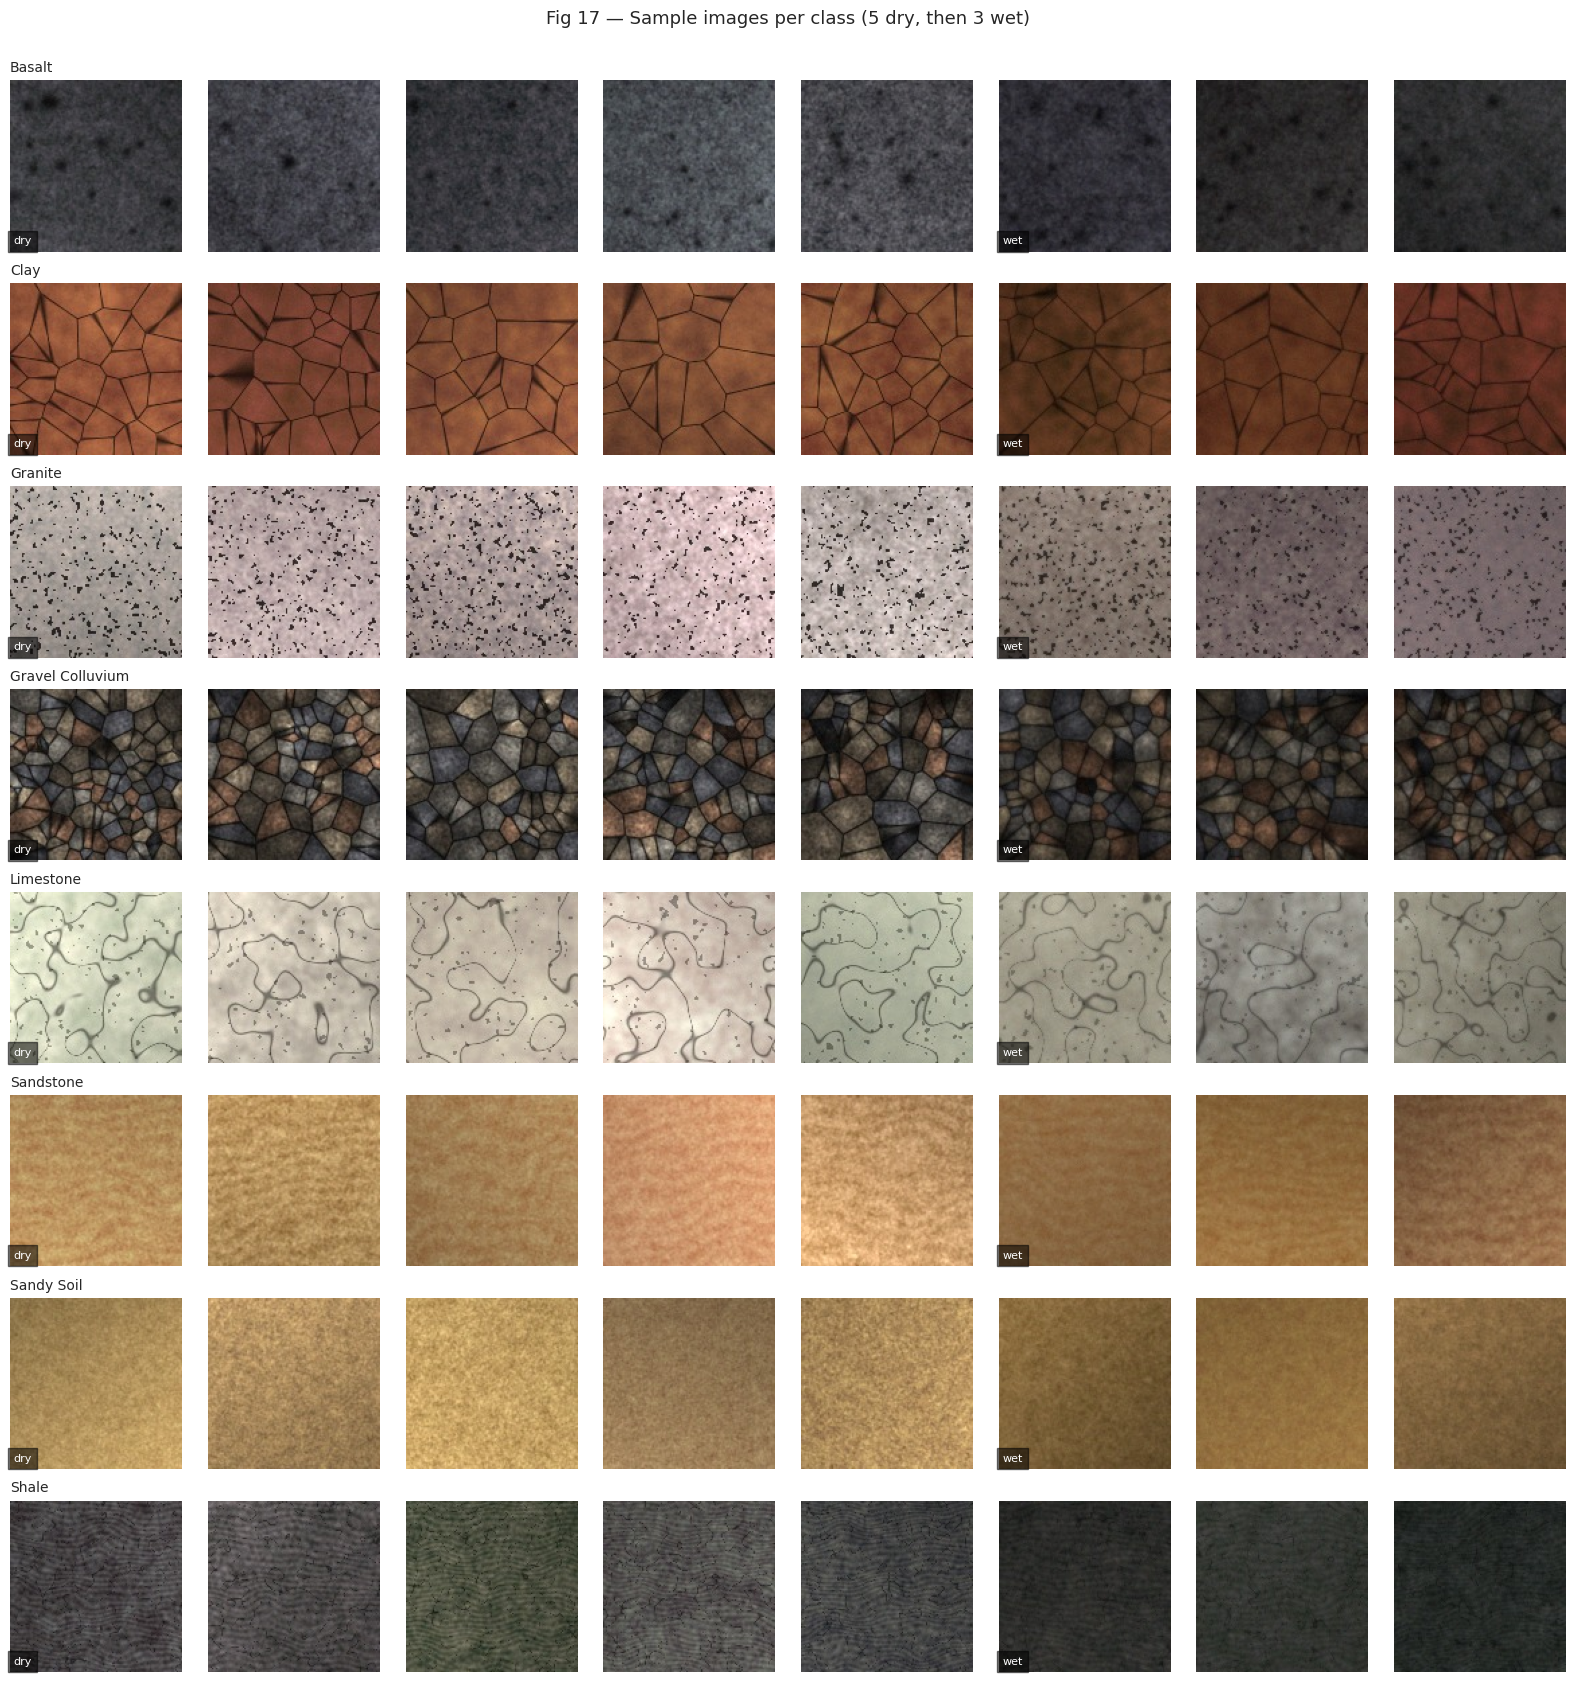

In [22]:
classes = list(imgs.material.unique())
fig, axes = plt.subplots(len(classes), 8, figsize=(16, 2.1 * len(classes)))
for r, cl in enumerate(classes):
    sub = imgs[imgs.material == cl]
    pick = list(sub[sub.moisture_state == "dry"].filepath[:5]) + list(sub[sub.moisture_state == "wet"].filepath[:3])
    for c, p in enumerate(pick):
        axes[r, c].imshow(Image.open(os.path.join(RAW, p))); axes[r, c].axis("off")
        if c == 0: axes[r, c].set_title(cl, fontsize=10, loc="left")
        if c in (0, 5): axes[r, c].text(2, 122, "dry" if c == 0 else "wet", color="w", fontsize=8, backgroundcolor="#0008")
plt.suptitle("Fig 17 — Sample images per class (5 dry, then 3 wet)", y=1.0, fontsize=13); save("fig17_image_gallery")

**Interpretation.** Each class has a distinct visual signature: granite (dark speckles on light grain), basalt (dark, fine, vesicular), sandstone (warm colour with bedding), limestone (pale with veins),
shale (dark, finely laminated), clay (red-brown with polygonal desiccation cracks), sandy soil (fine granular tan), gravel colluvium (angular clasts with shadowed voids). Wet samples are visibly darker and lower in contrast.

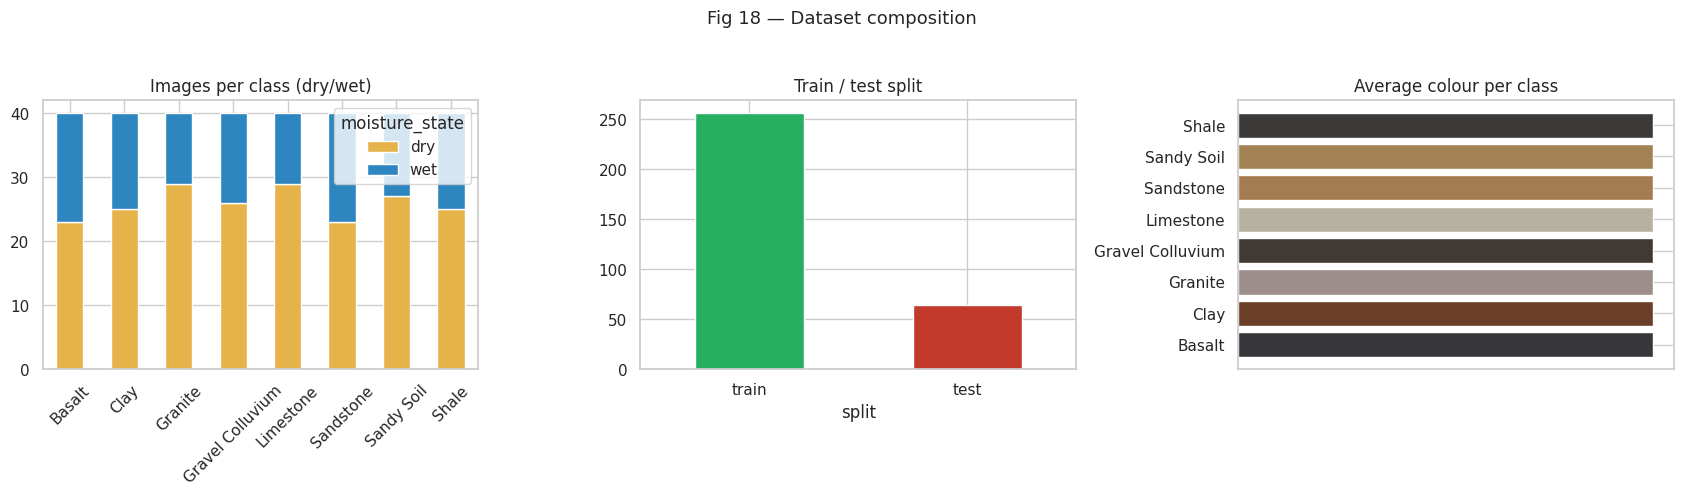

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ct = imgs.groupby(["material", "moisture_state"]).size().unstack(fill_value=0); ct.plot(kind="bar", stacked=True, ax=ax[0], color=["#e6b34a", "#2e86c1"]); ax[0].set(title="Images per class (dry/wet)", xlabel="")
ax[0].tick_params(axis="x", rotation=45)
imgs.split.value_counts().plot(kind="bar", ax=ax[1], color=["#27ae60", "#c0392b"]); ax[1].set(title="Train / test split"); ax[1].tick_params(axis="x", rotation=0)
means = imgs.groupby("material")[["mean_r", "mean_g", "mean_b"]].mean()
for i, (name, row) in enumerate(means.iterrows()): ax[2].barh(i, 1, color=np.clip(row.values, 0, 1))
ax[2].set_yticks(range(len(means))); ax[2].set_yticklabels(means.index); ax[2].set_xticks([]); ax[2].set_title("Average colour per class")
plt.suptitle("Fig 18 — Dataset composition", y=1.03, fontsize=13); save("fig18_image_composition")

**Interpretation.** The dataset is perfectly balanced (40 per class; 32 train / 8 test each, stratified) with roughly one-third wet images in every class — so any classifier accuracy cannot be an artefact of
class imbalance. The average-colour swatches confirm that colour alone is informative (reddish clay, tan sand/sandstone, dark basalt/shale) but also that several classes share similar colours, so **texture** is needed to separate them.

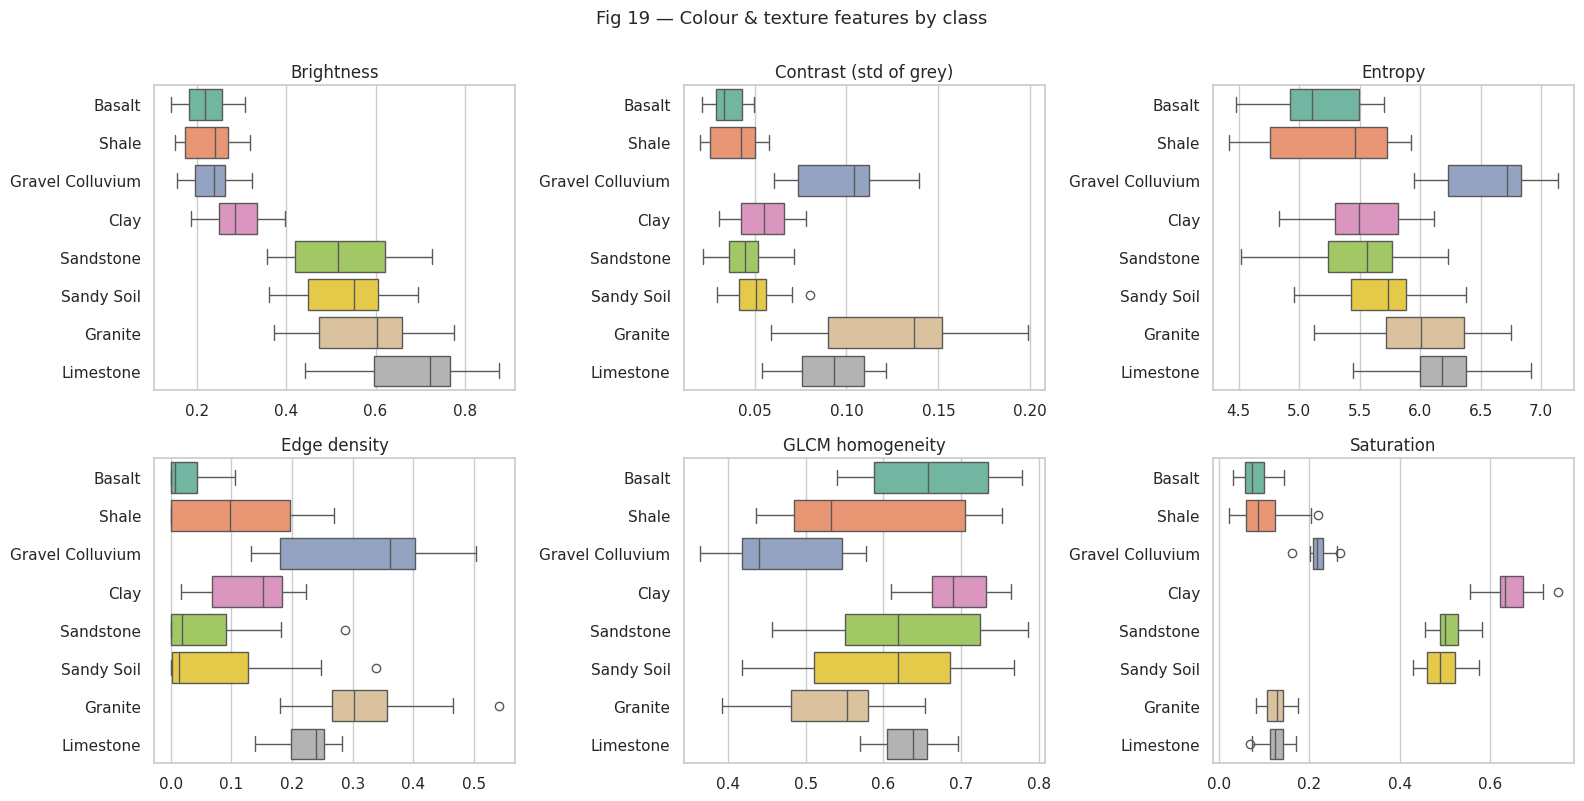

In [24]:
tf = [("brightness", "Brightness"), ("contrast", "Contrast (std of grey)"), ("entropy", "Entropy"), ("edge_density", "Edge density"), ("glcm_homogeneity", "GLCM homogeneity"), ("saturation", "Saturation")]
order = imgs.groupby("material").brightness.mean().sort_values().index
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (c, t) in zip(axes.ravel(), tf):
    sns.boxplot(data=imgs, y="material", x=c, order=order, palette="Set2", ax=ax); ax.set_title(t); ax.set_ylabel(""); ax.set_xlabel("")
plt.suptitle("Fig 19 — Colour & texture features by class", y=1.0, fontsize=13); save("fig19_texture_features")

**Interpretation.** Brightness separates dark classes (basalt, shale, gravel) from light ones (limestone, granite). Edge density and entropy pick out the textured classes (granite speckle, gravel clasts, clay cracks)
from the smooth ones (basalt, sandstone, sandy soil). GLCM homogeneity is lowest for gravel and granite (busy texture). No single feature separates all eight classes, but **combinations do**.

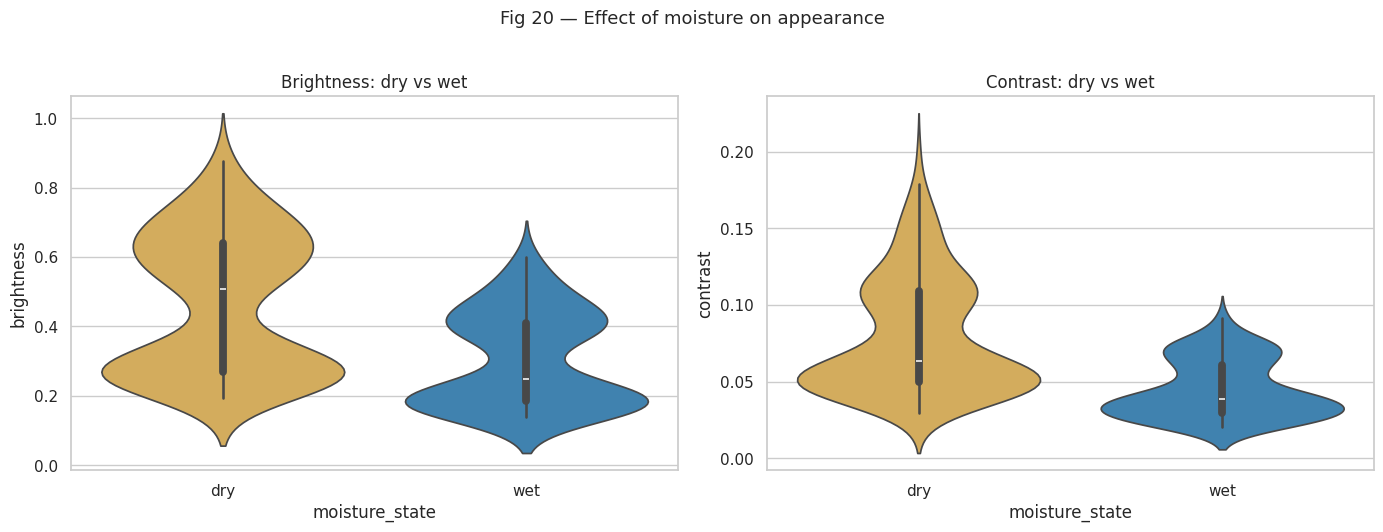

                brightness  contrast  saturation
moisture_state                                  
dry                  0.467     0.080       0.272
wet                  0.304     0.045       0.314
Brightness drop when wet: 35%


In [25]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
sns.violinplot(data=imgs, x="moisture_state", y="brightness", palette=["#e6b34a", "#2e86c1"], ax=ax[0], order=["dry", "wet"]); ax[0].set_title("Brightness: dry vs wet")
sns.violinplot(data=imgs, x="moisture_state", y="contrast", palette=["#e6b34a", "#2e86c1"], ax=ax[1], order=["dry", "wet"]); ax[1].set_title("Contrast: dry vs wet")
plt.suptitle("Fig 20 — Effect of moisture on appearance", y=1.02, fontsize=13); save("fig20_moisture_effect")
g = imgs.groupby("moisture_state")[["brightness", "contrast", "saturation"]].mean().round(3); print(g)
print("Brightness drop when wet: {:.0%}".format(1 - g.loc['wet','brightness'] / g.loc['dry','brightness']))

**Interpretation.** Wet material is on average about **35 % darker** and has visibly lower contrast, with slightly higher saturation. This matters for slope monitoring: saturation is the trigger for many failures,
so image brightness is a plausible *visual proxy for moisture* — but it also means a classifier trained mostly on dry images will mis-identify wet rock. Balanced dry/wet coverage (as here) is a requirement, not an option.

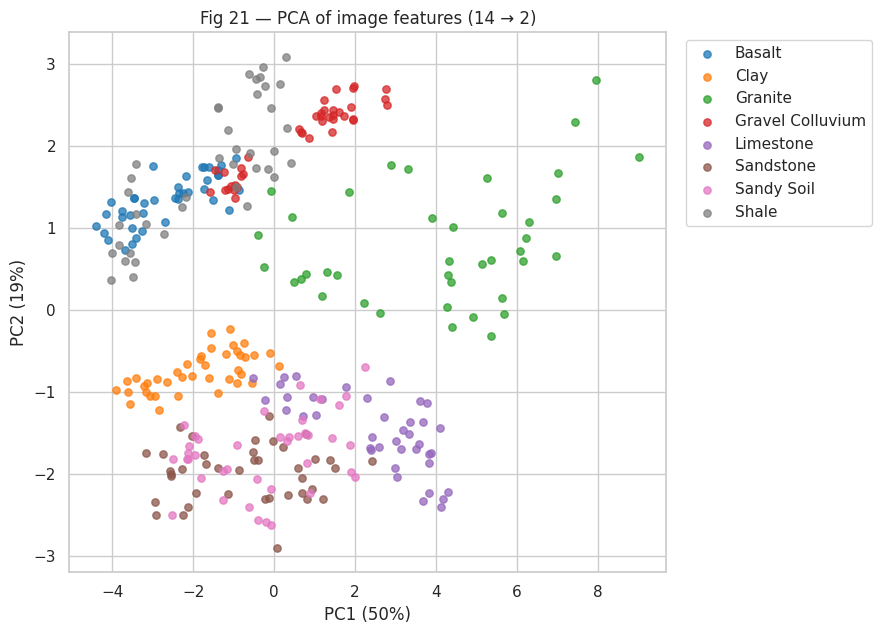

In [26]:
FCOLS = ["mean_r","mean_g","mean_b","brightness","contrast","saturation","hue","entropy","edge_density","sharpness","glcm_contrast","glcm_homogeneity","glcm_energy","glcm_correlation"]
Zi = (imgs[FCOLS] - imgs[FCOLS].mean()) / imgs[FCOLS].std()
U, S, Vt = np.linalg.svd(Zi.values - Zi.values.mean(0), full_matrices=False); pc = U[:, :2] * S[:2]; ev = S ** 2 / (S ** 2).sum()
plt.figure(figsize=(9, 6.5)); pal = dict(zip(classes, sns.color_palette("tab10", len(classes))))
for cl in classes:
    m_ = (imgs.material == cl).values; plt.scatter(pc[m_, 0], pc[m_, 1], s=28, alpha=.75, color=pal[cl], label=cl)
plt.xlabel(f"PC1 ({ev[0]:.0%})"); plt.ylabel(f"PC2 ({ev[1]:.0%})"); plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.title("Fig 21 — PCA of image features (14 → 2)")
save("fig21_image_pca")

**Interpretation.** Most classes form their own clusters even in just two dimensions. The tan classes (sandstone and sandy soil) overlap most, and the dark fine-grained classes (basalt, shale) sit close together —
these are the pairs a classifier is most likely to confuse (confirmed in Fig 22).

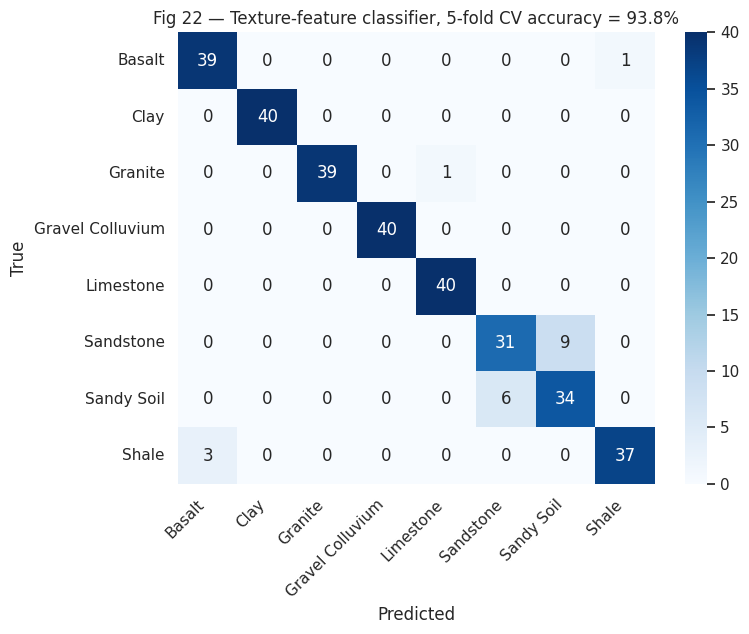

                  precision    recall  f1-score   support

          Basalt      0.929     0.975     0.951        40
            Clay      1.000     1.000     1.000        40
         Granite      1.000     0.975     0.987        40
Gravel Colluvium      1.000     1.000     1.000        40
       Limestone      0.976     1.000     0.988        40
       Sandstone      0.838     0.775     0.805        40
      Sandy Soil      0.791     0.850     0.819        40
           Shale      0.974     0.925     0.949        40

        accuracy                          0.938       320
       macro avg      0.938     0.938     0.937       320
    weighted avg      0.938     0.938     0.937       320



In [27]:
try:
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.model_selection import cross_val_predict, StratifiedKFold
    from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
    y = imgs.material.astype(str).to_numpy()
    pred = cross_val_predict(RandomForestClassifier(300, random_state=0), imgs[FCOLS], y, cv=StratifiedKFold(5, shuffle=True, random_state=0))
    cm = confusion_matrix(y, pred, labels=classes)
    plt.figure(figsize=(8, 6.5)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Fig 22 — Texture-feature classifier, 5-fold CV accuracy = {accuracy_score(y, pred):.1%}")
    plt.xticks(rotation=45, ha="right"); save("fig22_image_confusion")
    print(classification_report(y, pred, digits=3))
except ImportError:
    print("scikit-learn not installed - skipping this optional check (pip install scikit-learn)")

**Interpretation.** A simple Random Forest on the 14 hand-crafted features separates the eight classes with ≈94 % cross-validated accuracy. Six of eight classes reach F1 ≥ 0.95; the main confusion is
**sandstone ↔ sandy soil** (F1 ≈ 0.81), exactly the overlapping pair seen in the PCA. This shows the extracted features capture real visual differences. **Caveat:** these are clean procedural textures, so this is an *upper bound* — real field photographs (shadows, dust, mixed lithology, varying camera) will score lower.

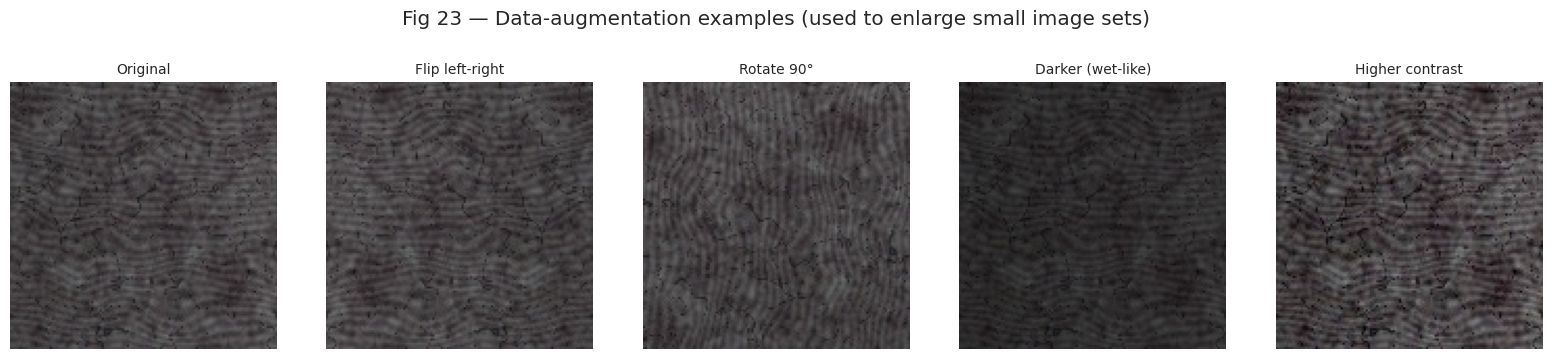

Whole dataset after per-channel standardisation: mean = [0. 0. 0.]  std = [1. 1. 1.]


In [28]:
sample = Image.open(os.path.join(RAW, imgs[imgs.material == "Shale"].filepath.iloc[0])).convert("RGB")
from PIL import ImageEnhance
aug = {"Original": sample, "Flip left-right": sample.transpose(Image.FLIP_LEFT_RIGHT), "Rotate 90°": sample.rotate(90),
       "Darker (wet-like)": ImageEnhance.Brightness(sample).enhance(0.65), "Higher contrast": ImageEnhance.Contrast(sample).enhance(1.5)}
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
for ax, (k, v) in zip(axes, aug.items()): ax.imshow(v); ax.set_title(k, fontsize=10); ax.axis("off")
plt.suptitle("Fig 23 — Data-augmentation examples (used to enlarge small image sets)", y=1.05); save("fig23_augmentation")
mu, sd = np.array(istats["channel_mean_rgb"]), np.array(istats["channel_std_rgb"])
allpix = np.stack([np.asarray(Image.open(os.path.join(RAW, p)).convert("RGB").resize((128, 128)), np.float32) / 255 for p in imgs.filepath])
std_pix = (allpix - mu) / sd
print("Whole dataset after per-channel standardisation: mean =", std_pix.mean((0, 1, 2)).round(3), " std =", std_pix.std((0, 1, 2)).round(3))

**Interpretation.** Flips and 90° rotations are safe augmentations for rock textures (no fixed "up" direction in a close-up), and brightness/contrast changes simulate wet/dry and lighting variation.
Pixel standardisation with the dataset's own channel mean/std (saved in `image_channel_stats.json`) is the last step before feeding images to a neural network.

---
# Summary — preprocessing outcome and business insights
### Preprocessing results
| Source | Raw → clean | Main fixes |
|---|---|---|
| Slope monitoring | 1,245 → 1,200 rows | 45 duplicates removed · 413 missing cells + 34 invalid values imputed · dates/labels/flags standardised · -999 sentinel and impossible values nulled · missing FoS recomputed with physics |
| Rock & soil | 488 → 480 rows | 26 rows with inconsistent names (23 spellings of 8 materials) unified · 8 duplicates removed · 10 unit-weight rows converted · typos nulled · group-median imputation |
| Images | 320 → 320 images | readability, duplicate and quality checks · 14 features extracted · channel statistics · stratified 80/20 split |

Validation against the known truth: non-imputed fields restored 100 %, imputed numeric fields ≈ 96–97 % exact with small average error, Factor of Safety recovered exactly.

### Insights for the mine (from this demo data)
1. **Slope angle is the strongest controllable driver of stability** (r = −0.76 with FoS) — bench-angle design has the biggest leverage.
2. **Pore pressure / groundwater** separate risk classes clearly (median 73 → 212 kPa, Low → Critical) — drainage and dewatering are the main mitigation lever; the two variables are ~96 % redundant.
3. **Recent blasting raises the average risk class** (2.13 → 2.45) — schedule blasts away from already marginal sectors.
4. **Weak, porous, weathered material (shale, clay, near-surface weathered rock) is the natural failure candidate**; weathering falls with depth.
5. **Wet material is ≈35 % darker in images** — brightness is a usable visual proxy for moisture, if imaging conditions are controlled.

### Limitations to state in the report
* All data are synthetic. Class balance is skewed (Low = 2.5 %) and 93 % of records have FoS < 1 — unlike a real operating mine — so **accuracy should not be used alone; report per-class recall / F1.**
* Rainfall shows no direct correlation with risk here and sector/time carry no signal — properties of the generator, not of real mines.
* Image features come from procedural textures; ≈94 % classification accuracy is an upper bound for real photographs.